<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ BDC Satria Data 2026: Klasifikasi Sampah dengan ConvNeXtV2 Freeze-Backbone ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>v4: ablation terkontrol freeze-backbone terhadap v3 full fine-tune, data identik submission #1</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **Tim IndomaretLabtekV (kode kelompok SD2026040000412)**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Verifikasi Struktur Data dan Guard Versi Data**](#3)
4. [**Analisis Data Eksploratif dan Integritas File**](#4)
5. [**Fold: Recompute Deterministik**](#5)
6. [**Dataset, Augmentasi, Loss, dan Mixup/CutMix**](#6)
7. [**Pemodelan: Backbone Beku + Head Terlatih**](#7)
8. [**Training, Soup, dan Ablation TTA**](#8)
9. [**Evaluasi dan Perbandingan dengan v3**](#9)
10. [**Inferensi dan Submission**](#10)
11. [**Analisis Error dan Grad-CAM**](#11)
12. [**Catatan Operasional (Kaggle)**](#12)
13. [**Daftar Pustaka**](#13)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi dan Status Tim

Kompetisi BDC Satria Data 2026: klasifikasi citra sampah ke 3 kelas (juknis SS4): **0 = Recyclable, 1 = Electronic, 2 = Organic**. Metrik: **Macro-averaged F1-Score**. Platform run: Kaggle Notebook, GPU T4 x2 (notebook ini sengaja memakai 1 GPU, lihat bagian Pemodelan).

Status saat notebook ini ditulis (21 Juli 2026):

- Submission #1 sudah terpakai: v3 ConvNeXtV2-Base **full fine-tune** pada data ronde-1 relabel, OOF pooled 5-fold **0.9844**, skor leaderboard **98,0473**.
- Selisih OOF terhadap LB: **-0.39 poin**. Ini bukti empiris pertama bahwa OOF train-side tim ini tidak sepenuhnya bisa diandalkan memprediksi LB.
- Sisa jatah: **2 submission**. Deadline 30 Juli 2026 16:00 WIB.

Notebook ini adalah kandidat submission #2 dan **belum pernah dieksekusi di mana pun** sebelum run Kaggle pertamanya. Verifikasi pra-run dilakukan lewat pengecekan sintaksis statis dan pembacaan ulang penuh.

## Pendekatan v4: Freeze-Backbone sebagai Ablation Terkontrol

**Satu-satunya variabel yang berubah dari v3 adalah strategi training**: seluruh backbone ConvNeXtV2 dibekukan permanen (`requires_grad=False`), hanya classifier head yang dilatih. Data, augmentasi, loss, sampler, fold, soup, dan protokol TTA identik v3. Panitia sudah mengonfirmasi eksplisit bahwa freeze backbone + latih head tetap dihitung transfer learning/fine-tuning yang sah.

```
ConvNeXtV2-Base fcmae_ft_in22k_in1k  (87.7M param, SELURUHNYA BEKU)
    |
    global pool + LayerNorm  (head.norm, ikut terlatih: bagian dari head timm)
    |
    Linear(1024, 512) -> GELU -> Dropout(0.3)     <- head MLP kecil (CFG.HEAD_HIDDEN=512)
    |
    Linear(512, 3) -> logit kelas
```

**Dasar teknis keputusan freeze** (bukan ikut-ikutan tim lain):

1. **Bukti langsung**: OOF 0.9844 vs LB 98,0473 (-0.39). Model full fine-tune 87M parameter menggeneralisasi ke test panitia lebih buruk daripada estimasi OOF-nya sendiri.
2. **Hipotesis kerja** (CONTEXT.md Bagian 1): full fine-tune punya kapasitas menghafal noise label, termasuk kemungkinan konvensi relabel manual tim yang tidak 100% sama dengan konvensi ground truth panitia. Backbone beku membatasi kapasitas itu: fitur ImageNet tidak bisa "membengkokkan diri" mengikuti noise, hanya head kecil yang beradaptasi. Regularisasi struktural semacam ini jauh lebih kuat daripada dropout/weight decay.
3. **Catatan interpretasi log v3** (kalibrasi klaim): `train_f1` 0.87-0.90 vs `val_f1` 0.98+ di semua fold v3 sering dibaca sebagai bukti overfit, tetapi sebagian besar depresi `train_f1` itu artefak metrik mixup (pada batch ter-mix, F1 train dihitung terhadap label asli; komentar di `run_epoch` v3 sudah menandainya "indikator kasar"). Bukti gap generalisasi yang solid tetap poin 1. Freeze diuji karena poin 1 dan 2, bukan karena angka `train_f1` itu sendiri.
4. **Preseden referensi**: findit-v17 (finalis DAC) memakai DINOv3 fully-frozen + head MLP; DSC0118 memakai DINOv3-Huge frozen + linear head; template DINOv3 dan notebook gemastik segmentation juga default `freeze_backbone=True` untuk menekan overfit. Di domain waste, fitur pretrained tanpa fine-tune terbukti informatif (DECMCV, arXiv 2503.02241).

**Kalibrasi ekspektasi**: tidak ada teknik yang menjamin skor LB tertentu, dan notebook ini tidak mengklaim angka apa pun. Freeze-backbone bisa saja menghasilkan OOF lebih rendah dari v3 (linear/MLP probe umumnya di bawah plafon full fine-tune saat label bersih); nilai eksperimen ini justru pada pasangan angka (OOF v4, LB v4) vs (OOF v3, LB v3) untuk melihat apakah gap OOF-LB menyempit. Keputusan submit tetap di tangan user dengan sisa 2 jatah.

**Kontrak data**: dataset yang di-attach WAJIB dataset ronde-1 relabel yang sama persis dengan submission #1, distribusi `{"0_Recyclable": 10078, "1_Electronic": 3968, "2_Organic": 12481}`. Guard versi data akan menghentikan run pada data lain (termasuk ronde-2/3/4/5 yang lebih baru) supaya sifat ablation terkontrol tidak rusak diam-diam.

## Referensi Utama

Notebook referensi (pola struktural dan resep):

- `ref/findit-v17.ipynb`: DINOv3 ViT-H+ fully-frozen + head `Linear-GELU-Dropout(0.3)-Linear`, head LR 3e-4, assert jumlah parameter backbone unfrozen == 0, ablation TTA. Sumber pola narasi notebook ini.
- `ref/ver34_clean_end_to_end.ipynb`: head search (linear vs MLP vs multi-sample dropout), TTA divalidasi di val sebelum dipakai di test, audit reproducibility.
- `ref/DSC0118_Over_Under 35.5_Notebook.ipynb`: DINOv3-Huge frozen + `nn.Linear` tunggal, head LR 1e-3, guard `RuntimeError` bila tidak ada parameter trainable.
- `ref/image_classification_dinov3_template.ipynb`: frozen backbone + head `LayerNorm-Dropout(0.2)-Linear`, LR 2e-4 (base) sampai 8e-5 (huge).
- `ref/pelatihan-gemastik-image-segmentation.ipynb` (baru): DINOv2 frozen + decoder terlatih; optimizer HANYA menerima parameter `requires_grad=True`; justifikasi freeze untuk dataset kecil.
- `ref/pelatihan-gemastik-image-clasification.ipynb` (baru): CRNN+CTC from scratch untuk multi-digit; tidak ada pola freeze yang applicable, tetapi menegaskan pola early stopping + cosine + AMP + grad clip yang juga dipakai di sini.
- `v3-convnext.ipynb`: sumber resep inti yang diport utuh (guard data, scan integritas, dedup, fold, augmentasi, loss, soup, exact-match, verifikasi submission).

Paper (daftar lengkap di Daftar Pustaka): DECMCV (2503.02241), Garbage Dataset (2602.10500), model soups (2603.02181), TTA-can-hurt (2604.09697), GTTA (2507.01347), S2-FracMix (2606.25784), optic plastics (2505.16513), WaRP/Sayem NCA 2025, review industrial waste (IEEE Access 2025), Heliyon 2024.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Seluruh impor dikelompokkan satu sel. Seed disetel untuk semua sumber keacakan; `cudnn.benchmark` aktif (autotune conv, lebih cepat) karena determinisme bitwise tidak disyaratkan. Environment target run ini **hanya Kaggle T4x2**; fallback path lokal dipertahankan minimal untuk pembacaan kode, bukan untuk eksekusi.

In [1]:
import glob
import hashlib
import math
import os
import platform
import random
import signal
import time
from contextlib import nullcontext
from datetime import date
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from timm.data import resolve_model_data_config
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None  # data kompetisi (trusted); foto besar jangan dianggap decompression bomb


def seed_everything(seed: int = 42, deterministic: bool = True):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = deterministic
    torch.backends.cudnn.benchmark = not deterministic  # benchmark aktif = autotune conv, jauh lebih cepat


def rss_gb():
    """RSS proses saat ini dalam GB (observability RAM). Kaggle = Linux, /proc tersedia."""
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1024 ** 2
    except Exception:
        pass
    return float("nan")


# Verifikasi hardware SEBELUM asumsi apa pun
DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
N_GPUS = torch.cuda.device_count()
print("torch :", torch.__version__, "| timm :", timm.__version__, "| platform:", platform.system())
print("device:", DEVICE, "| jumlah GPU CUDA:", N_GPUS)
for i in range(N_GPUS):
    props = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {props.name} | {props.total_memory / 1024 ** 3:.1f} GB VRAM")
if DEVICE.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True  # no-op di T4 (Turing), berguna bila GPU Ampere+
    torch.backends.cudnn.allow_tf32 = True

torch : 2.10.0+cu128 | timm : 1.0.26 | platform: Linux
device: cuda | jumlah GPU CUDA: 2
  GPU 0: Tesla T4 | 14.6 GB VRAM
  GPU 1: Tesla T4 | 14.6 GB VRAM


## Settings

Kelas `CFG` memusatkan seluruh konfigurasi. Resep training identik v3 kecuali yang secara logis harus berubah karena backbone beku; setiap perubahan diberi komentar `# v3: <nilai lama>` supaya diff resep bisa diaudit dari satu tempat. Pencarian root dataset memakai pola v3 yang sudah teruji di Kaggle (lessons.md 2026-07-13 dan 2026-07-16): coba path known-good dulu, lalu glob recursive `**` dengan filter tanda tangan isi folder, dan STOP bila kandidat tidak tepat satu.

In [2]:
def running_on_kaggle() -> bool:
    return Path("/kaggle/input").exists() or bool(os.getenv("KAGGLE_KERNEL_RUN_TYPE"))


ON_KAGGLE = running_on_kaggle()
# Path dataset run v3: dicoba lebih dulu, TAPI tidak pernah diasumsikan ada (slug/kedalaman bisa berubah)
KAGGLE_DATA_ROOT = Path("/kaggle/input/datasets/riantamaputra/bdc-2026-waste-classification-dataset")


def is_data_root(p) -> bool:
    """Root data valid = submission.csv + subfolder train/ + test/ sekaligus dalam satu folder."""
    p = Path(p)
    return (p / "submission.csv").is_file() and (p / "train").is_dir() and (p / "test").is_dir()


def resolve_kaggle_data_root() -> Path:
    """Cari root dataset di /kaggle/input tanpa mengasumsikan kedalaman path (pola v3, teruji run #1).

    0 kandidat = STOP; > 1 kandidat = STOP dengan daftar kandidat. Notebook tidak pernah menebak,
    karena salah pilih dataset = training di data versi lain dan ablation-nya rusak diam-diam.
    """
    if is_data_root(KAGGLE_DATA_ROOT):
        print("Root dataset Kaggle: path known-good run v3 dipakai apa adanya.")
        return KAGGLE_DATA_ROOT
    cands = sorted({str(Path(p).parent)
                    for p in glob.glob("/kaggle/input/**/submission.csv", recursive=True)
                    if is_data_root(Path(p).parent)})
    assert cands, (
        "Dataset kompetisi TIDAK ditemukan di /kaggle/input. Attach dataset ronde-1 relabel yang sama "
        "dengan submission #1 (submission.csv + folder train/ + test/), lalu jalankan ulang. "
        f"Path yang dicoba pertama: {KAGGLE_DATA_ROOT}")
    assert len(cands) == 1, (
        f"Ada {len(cands)} kandidat root dataset di /kaggle/input: {cands}. AMBIGU, notebook tidak menebak "
        "(salah pilih = training di data versi lain, ablation terhadap v3 rusak). Detach yang tidak "
        "dipakai, atau set KAGGLE_DATA_ROOT langsung ke root yang benar lalu jalankan ulang cell ini.")
    print("Root dataset Kaggle ditemukan via pencarian recursive:", cands[0])
    return Path(cands[0])


KAGGLE_DATA_ROOT_RESOLVED = resolve_kaggle_data_root() if ON_KAGGLE else None


class CFG:
    SEED = 42
    RUN_NAME = "v4_freeze_convnext"
    GROUP_CODE = "SD2026040000412"  # kode kelompok; nama file submission = submission_<GROUP_CODE>.csv

    ON_KAGGLE = ON_KAGGLE
    DATA_ROOT = KAGGLE_DATA_ROOT_RESOLVED if ON_KAGGLE else Path.cwd()
    OUTPUT_ROOT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()
    TRAIN_DIR = DATA_ROOT / "train"
    TEST_DIR = DATA_ROOT / "test"
    TEMPLATE_PATH = DATA_ROOT / "submission.csv"
    EXP_DIR = OUTPUT_ROOT / "experiments" / RUN_NAME
    LOG_PATH = OUTPUT_ROOT / "experiments" / "EXPERIMENTS_LOG.md"
    SUBMISSION_DIR = OUTPUT_ROOT / "outputs"

    # Mapping resmi juknis SS4, jangan diubah
    LABEL_NAMES = {0: "Recyclable", 1: "Electronic", 2: "Organic"}
    NUM_CLASSES = 3

    # KONTRAK ABLATION: data WAJIB identik submission #1 (ronde-1 relabel, 111 file dipindah label).
    # Distribusi lain (termasuk ronde-2/3/4/5 yang lebih baru) dihentikan fail-fast.
    EXPECTED_CLASS_COUNTS = {"0_Recyclable": 9999, "1_Electronic": 3961, "2_Organic": 12567}
    ALLOW_DATA_DRIFT = False  # True HANYA kalau sadar sedang memakai versi data lain (catat di log!)

    MODEL_ID = "convnextv2_base.fcmae_ft_in22k_in1k"
    IMG_SIZE = 224
    DROP_PATH_RATE = 0.0     # v3: 0.1. Stochastic depth hidup di blok backbone; dengan backbone beku
                             # ia cuma membuat "fitur beku" jadi stokastik tanpa bisa diadaptasi.
                             # 0.0 = fitur deterministik, semantik freeze bersih (narasi bagian 7).
    FREEZE_BACKBONE = True   # dokumentasi keputusan inti v4; di-ASSERT di build_model, bukan saklar
                             # (pola "keputusan mati = assert" dari USE_DATA_PARALLEL, lessons 2026-07-16)

    # Head: 0 = linear probe murni (head.fc bawaan timm); >0 = MLP kecil Linear-GELU-Dropout-Linear
    # (pola findit-v17 frozen; ver34 head-search juga memilih head lebih kaya dari linear tunggal)
    HEAD_HIDDEN = 512
    HEAD_DROPOUT = 0.3       # angka findit-v17; penjaga overfit head satu-satunya modul berkapasitas

    # Referensi pembanding v3 (data & fold identik, lihat bagian 5; TIDAK ada target skor di sini)
    REF_V3_OOF_POOLED = 0.9844   # OOF pooled 5-fold v3 (seleksi TTA), data ronde-1
    REF_V3_LB = 98.0473          # skor leaderboard submission #1 (skala 0-100); konteks, bukan acuan seleksi

    # Training: identik v3 kecuali bertanda "v3:"
    N_FOLDS = 5
    TRAIN_FOLDS = [0, 1, 2, 3, 4]
    EPOCHS = 15
    BATCH_SIZE = 32
    GRAD_ACCUM_STEPS = 1
    NUM_WORKERS = 4          # dioverride di bawah bila bukan Kaggle
    HEAD_LR = 4e-4           # = HEAD_LR v3 persis; juga di tengah rentang referensi frozen
                             # (2e-4 template dinov3-base, 3e-4 findit-v17, 1e-3 DSC0118)
    WEIGHT_DECAY = 1e-4
    EARLY_STOPPING_PATIENCE = 3
    GRAD_CLIP_NORM = 1.0
    FOCAL_GAMMA = 2.0
    LABEL_SMOOTHING = 0.05
    USE_VAL_TTA = True       # metrik seleksi epoch konsisten dengan kondisi inferensi (pola ver34)
    # v3: BACKBONE_LR / FREEZE_BACKBONE_EPOCHS / USE_LLRD dihapus, tidak bermakna saat backbone beku

    # Augmentasi & mixup identik v3 (kontrol ablation; justifikasi bagian 6)
    USE_VFLIP = True
    MIX_PROB = 0.5
    MIXUP_ALPHA = 0.2
    CUTMIX_ALPHA = 1.0

    # Greedy model soup per fold (arXiv 2603.02181), identik v3. Backbone beku identik antar
    # checkpoint, jadi rata-rata bobot efektif hanya meratakan head; tetap satu model.
    USE_GREEDY_SOUP = True
    SOUP_TOPK = 5

    HEARTBEAT_EVERY_BATCH = 50
    DECODE_TIMEOUT_S = 20
    CUDNN_DETERMINISTIC = False
    RESIZE_MP_THRESHOLD = 8_000_000
    RESIZE_MAX_SIDE = 1024
    MAX_DECODE_SIDE = 1024
    USE_DATA_PARALLEL = False  # keputusan final v1 (leak RAM broadcast DataParallel di T4x2);
                               # maybe_data_parallel() meng-assert flag ini tetap False.
    CHANNELS_LAST = True       # conv net + AMP: layout NHWC lebih cepat

    SMOKE_TEST = False
    SMOKE_PER_CLASS = 40
    SMOKE_TEST_IMAGES = 64


if not ON_KAGGLE:
    CFG.NUM_WORKERS = 2
if CFG.SMOKE_TEST:
    CFG.TRAIN_FOLDS = [0]
    CFG.EPOCHS = 2  # 2 epoch supaya jalur soup (>= 2 kandidat checkpoint) ikut teruji
    CFG.BATCH_SIZE = 8
    CFG.NUM_WORKERS = 2

# pin_memory OFF di Kaggle (suspek leak RAM, pelajaran v1); ON untuk CUDA lokal
PIN_MEMORY = DEVICE.type == "cuda" and not ON_KAGGLE

_hint = ("Di Kaggle: pastikan dataset kompetisi ronde-1 sudah di-attach (Add Input)."
         if ON_KAGGLE else "Jalankan notebook dari root project (sejajar folder train/ dan test/).")
assert CFG.TRAIN_DIR.is_dir(), f"Folder train tidak ditemukan: {CFG.TRAIN_DIR}\n{_hint}"
assert CFG.TEST_DIR.is_dir(), f"Folder test tidak ditemukan: {CFG.TEST_DIR}\n{_hint}"
assert CFG.TEMPLATE_PATH.is_file(), f"Template submission tidak ditemukan: {CFG.TEMPLATE_PATH}"

CFG.EXP_DIR.mkdir(parents=True, exist_ok=True)
CFG.SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG.SEED, deterministic=CFG.CUDNN_DETERMINISTIC)
print("ENV :", "Kaggle" if ON_KAGGLE else "lokal (hanya untuk baca kode; run resmi di Kaggle)")
print("DATA:", CFG.DATA_ROOT)
print("OUT :", CFG.OUTPUT_ROOT)
print("MODE:", "SMOKE_TEST (subset kecil, bukan hasil eksperimen)" if CFG.SMOKE_TEST else "FULL RUN")
print(f"batch={CFG.BATCH_SIZE} x accum={CFG.GRAD_ACCUM_STEPS} | workers={CFG.NUM_WORKERS} | pin_memory={PIN_MEMORY}")
print(f"freeze backbone={CFG.FREEZE_BACKBONE} | head_hidden={CFG.HEAD_HIDDEN} | head_lr={CFG.HEAD_LR:.0e}")

Root dataset Kaggle ditemukan via pencarian recursive: /kaggle/input/bdc-2026-waste-classification-dataset
ENV : Kaggle
DATA: /kaggle/input/bdc-2026-waste-classification-dataset
OUT : /kaggle/working
MODE: FULL RUN
batch=32 x accum=1 | workers=4 | pin_memory=False
freeze backbone=True | head_hidden=512 | head_lr=4e-04


## Bobot Pretrained

Bobot `convnextv2_base.fcmae_ft_in22k_in1k` diunduh `timm` dari HF Hub saat pertama dipakai (publik, tanpa token). Pretraining: self-supervised FCMAE lalu supervised fine-tune ImageNet-22k ke ImageNet-1k; bobot tidak pernah dilatih dengan data kompetisi ini (dokumentasi wajib juknis SS5, dan panitia mengonfirmasi pretrained publik sah). Di Kaggle: **Internet harus ON** saat commit supaya unduhan berhasil.

In [3]:
import urllib.request


def internet_ok(url="https://huggingface.co", timeout=10):
    try:
        urllib.request.urlopen(url, timeout=timeout)
        return True
    except Exception:
        return False


try:
    _probe = timm.create_model(CFG.MODEL_ID, pretrained=True, num_classes=0)
    del _probe
    print("Bobot pretrained tersedia (cache lokal atau unduhan barusan berhasil).")
except Exception as e:
    if internet_ok():
        raise
    raise RuntimeError(
        "Bobot pretrained belum ada di cache dan tidak ada koneksi ke huggingface.co. "
        "Di Kaggle: nyalakan Internet pada panel Settings notebook, lalu jalankan ulang.") from e

model.safetensors:   0%|          | 0.00/355M [00:00<?, ?B/s]

Bobot pretrained tersedia (cache lokal atau unduhan barusan berhasil).


## Observability

Pelajaran run v1/v2/v3: progress intra-epoch wajib terlihat. Heartbeat print (`flush=True`) tiap 50 batch menampilkan s/iter, RSS RAM (+delta), dan VRAM teralokasi. W&B opsional via secret `WANDB_API_KEY` (di-skip rapi kalau tidak ada; token tidak pernah dicetak).

In [4]:
try:
    import wandb
    WANDB_AVAILABLE = True
except ImportError:
    wandb = None
    WANDB_AVAILABLE = False

WANDB_PROJECT = "bdc-satria-data-2026"


def wandb_login():
    if not WANDB_AVAILABLE:
        print("Paket wandb tidak terinstall, logging W&B nonaktif.")
        return False
    api_key = os.getenv("WANDB_API_KEY")
    if not api_key and CFG.ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            api_key = UserSecretsClient().get_secret("WANDB_API_KEY")
        except Exception as e:
            print("Kaggle Secrets WANDB_API_KEY tidak bisa diambil:", repr(e))
    if not api_key:
        print("WANDB_API_KEY tidak tersedia; logging W&B nonaktif (heartbeat tetap tampil via print).")
        return False
    try:
        wandb.login(key=api_key)
        return True
    except Exception as e:
        print("Login W&B gagal:", repr(e))
        return False


WANDB_ENABLED = wandb_login()
print("W&B:", "AKTIF" if WANDB_ENABLED else "nonaktif")

Kaggle Secrets WANDB_API_KEY tidak bisa diambil: BackendError("Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 125761498 and label WANDB_API_KEY.'], 'error': {'code': 5}, 'wasSuccessful': False}.")
WANDB_API_KEY tidak tersedia; logging W&B nonaktif (heartbeat tetap tampil via print).
W&B: nonaktif


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Verifikasi Struktur Data dan Guard Versi Data <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Label tidak diasumsikan: struktur folder discan via kode dan mapping folder ke label di-assert terhadap juknis. **Guard versi data** memastikan `train/` adalah data ronde-1 relabel yang sama dengan submission #1 (10.078 / 3.968 / 12.481; total 26.527 karena cleaning murni relabel/move, zero delete). Run pada distribusi lain dihentikan fail-fast: itu perilaku benar, bukan bug, karena satu-satunya tujuan v4 adalah perbandingan apples-to-apples terhadap v3.

In [5]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted([p for p in CFG.TRAIN_DIR.iterdir() if p.is_dir()])
assert class_dirs, f"Tidak ada subfolder kelas di {CFG.TRAIN_DIR}"

dir_mapping = {}
for d in class_dirs:
    code_str, _, name = d.name.partition("_")
    assert code_str.isdigit() and name, f"Nama subfolder tidak berpola '<kode>_<NamaKelas>': {d.name}"
    dir_mapping[int(code_str)] = (name, d)

assert set(dir_mapping) == set(CFG.LABEL_NAMES), \
    f"Kode kelas folder {sorted(dir_mapping)} != juknis {sorted(CFG.LABEL_NAMES)}"
for label_code, (name, _) in dir_mapping.items():
    assert name == CFG.LABEL_NAMES[label_code], (
        f"Nama kelas folder '{name}' (kode {label_code}) != juknis '{CFG.LABEL_NAMES[label_code]}'")
print("Mapping folder -> label terverifikasi sesuai juknis:", {k: v[0] for k, v in sorted(dir_mapping.items())})

train_rows = []
per_dir_counts = {}
for label_code, (name, d) in sorted(dir_mapping.items()):
    files = [p for p in sorted(d.iterdir()) if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    per_dir_counts[d.name] = len(files)
    for p in files:
        train_rows.append({"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p),
                           "class_name": name, "label": label_code})
train_df = pd.DataFrame(train_rows)
print(f"Total gambar train: {len(train_df)} | per folder: {per_dir_counts}")

# Guard versi data: run nyata wajib di data ronde-1 relabel (identik submission #1)
if CFG.SMOKE_TEST:
    print("SMOKE_TEST: guard versi data dilewati (smoke boleh jalan di salinan data mana pun).")
elif per_dir_counts != CFG.EXPECTED_CLASS_COUNTS:
    msg = (f"VERSI DATA TIDAK SESUAI. Ditemukan {per_dir_counts}, diharapkan {CFG.EXPECTED_CLASS_COUNTS} "
           "(dataset ronde-1 relabel, identik submission #1). Kemungkinan ter-attach dataset versi lain "
           "(pra-cleaning ATAU ronde relabel yang lebih baru). Memakai data lain MERUSAK sifat ablation "
           "terkontrol v4 vs v3. Kalau memang disengaja: update CFG.EXPECTED_CLASS_COUNTS, catat di "
           "EXPERIMENTS_LOG, dan sadari hasilnya bukan lagi ablation. Override sadar: CFG.ALLOW_DATA_DRIFT=True.")
    if CFG.ALLOW_DATA_DRIFT:
        print("PERINGATAN (ALLOW_DATA_DRIFT=True):", msg)
    else:
        raise AssertionError(msg)
else:
    print("Guard versi data LULUS: distribusi kelas cocok dengan dataset ronde-1 (identik submission #1).")

test_paths = sorted([p for p in CFG.TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
subdirs_test = [p for p in CFG.TEST_DIR.iterdir() if p.is_dir()]
assert not subdirs_test, f"Tidak diduga: test/ punya subfolder {subdirs_test}"
test_id_to_path = {}
for p in test_paths:
    assert p.stem.isdigit(), f"Nama file test bukan angka murni: {p.name}"
    tid = int(p.stem)
    assert tid not in test_id_to_path, f"id test duplikat: {tid}"
    test_id_to_path[tid] = p
print(f"Total gambar test : {len(test_id_to_path)} | id min={min(test_id_to_path)} max={max(test_id_to_path)}")
assert set(test_id_to_path) == set(range(1, len(test_id_to_path) + 1)), "id test tidak kontinu 1..N"

Mapping folder -> label terverifikasi sesuai juknis: {0: 'Recyclable', 1: 'Electronic', 2: 'Organic'}


Total gambar train: 26527 | per folder: {'0_Recyclable': 9999, '1_Electronic': 3961, '2_Organic': 12567}
Guard versi data LULUS: distribusi kelas cocok dengan dataset ronde-1 (identik submission #1).


Total gambar test : 1458 | id min=1 max=1458


In [6]:
template_df = pd.read_csv(CFG.TEMPLATE_PATH)
display(template_df.head(3))
assert list(template_df.columns) == ["id", "predicted"], f"Kolom template tidak sesuai: {list(template_df.columns)}"
assert len(template_df) == len(test_id_to_path), \
    f"Baris template ({len(template_df)}) != jumlah file test ({len(test_id_to_path)})"
assert template_df["id"].is_unique, "id template tidak unik"
assert set(template_df["id"]) == set(test_id_to_path), "id template != id file test"

TEMPLATE_ID_ORDER = template_df["id"].tolist()
print(f"Template OK: {len(TEMPLATE_ID_ORDER)} id | awal {TEMPLATE_ID_ORDER[:5]} | akhir {TEMPLATE_ID_ORDER[-5:]}")

,id,predicted
0,1,NaN
1,2,NaN
2,3,NaN


Template OK: 1458 id | awal [1, 2, 3, 4, 5] | akhir [1454, 1455, 1456, 1457, 1458]


In [7]:
# Saat SMOKE_TEST: pangkas train agar seluruh pipeline terverifikasi cepat.
# Hasil smoke BUKAN hasil eksperimen: tidak dicatat ke EXPERIMENTS_LOG dan tidak menghasilkan submission.
if CFG.SMOKE_TEST:
    sampled_idx = []
    for _, g in train_df.groupby("label"):
        sampled_idx.extend(g.sample(min(len(g), CFG.SMOKE_PER_CLASS), random_state=CFG.SEED).index)
    train_df = train_df.loc[sorted(sampled_idx)].reset_index(drop=True)
    print(f"SMOKE_TEST: train_df dipangkas menjadi {len(train_df)} baris ({CFG.SMOKE_PER_CLASS}/kelas)")
else:
    print("FULL RUN: memakai seluruh train_df:", len(train_df), "baris")

FULL RUN: memakai seluruh train_df: 26527 baris


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif dan Integritas File <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

EDA penuh (resolusi, brightness, profil warna) sudah didokumentasikan di notebook v1 dan tetap berlaku: cleaning ronde-1 murni memindahkan 111 label, tidak menambah/menghapus gambar. Yang ditampilkan ulang di sini hanya yang MEMPENGARUHI pipeline run ini: distribusi kelas pasca-relabel, sampel visual per kelas, integritas decode, dedup exact, dan pre-resize gambar raksasa. Semua identik v3 supaya input model benar-benar sama.

,count,pct
class_name,,
Recyclable,9999,37.69
Electronic,3961,14.93
Organic,12567,47.37


Imbalance ratio (max/min): 3.17x


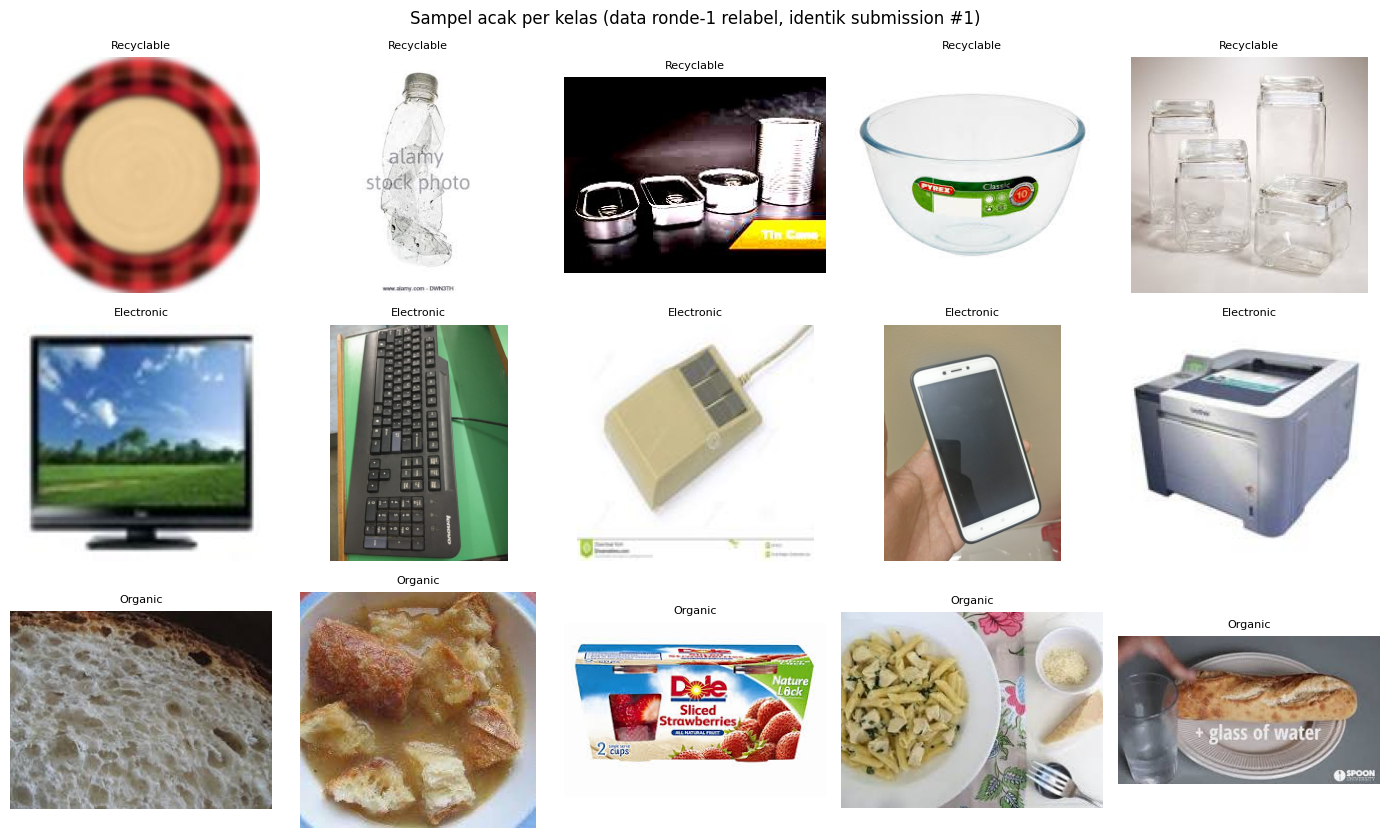

In [8]:
class_counts = train_df["class_name"].value_counts().reindex(
    [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)])
display(class_counts.to_frame("count").assign(pct=lambda d: (100 * d["count"] / d["count"].sum()).round(2)))
print(f"Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.2f}x")

fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
rng = np.random.RandomState(CFG.SEED)
for i in range(CFG.NUM_CLASSES):
    sub = train_df[train_df["label"] == i]
    picks = sub.iloc[rng.choice(len(sub), size=min(5, len(sub)), replace=False)]
    for j, (_, r) in enumerate(picks.iterrows()):
        img = Image.open(r["path"])
        img.draft("RGB", (512, 512))
        axes[i, j].imshow(ImageOps.exif_transpose(img).convert("RGB"))
        axes[i, j].set_title(r["class_name"], fontsize=8)
    for j in range(5):
        axes[i, j].axis("off")
plt.suptitle("Sampel acak per kelas (data ronde-1 relabel, identik submission #1)")
plt.tight_layout()
plt.show()

> ### Insights
> Electronic tetap kelas minoritas (sekitar 15%, imbalance sekitar 3.2x); `WeightedRandomSampler` + focal alpha `1/sqrt(count)` dipertahankan.
> Pasangan tersulit historis adalah **Recyclable vs Organic** (84.5% top error OOF v2), dan sebagian error itu terbukti label salah yang sudah diperbaiki di ronde-1.
> Sinyal warna adalah pembeda penting R vs O, karena itu ColorJitter tetap `hue=0` dan saturasi moderat, argumen yang sama dipakai ver34 dengan jitter konservatif.
> Relevansi khusus untuk v4: karena backbone beku, model hanya bisa memakai fitur warna/tekstur pretrained apa adanya; kalau OOF v4 jauh di bawah v3 khusus di pasangan R vs O, itu sinyal fitur ImageNet kurang diskriminatif untuk batas material dan head butuh kapasitas lebih (run B/C di Catatan Operasional).

### Integritas file: sha256 + validasi decode (jalur persis DataLoader)

Kaggle = Linux, `SIGALRM` tersedia sehingga timeout decode aktif. Scan di-cache per (relpath, size) sehingga run ulang cepat.

In [9]:
SCAN_VER = 3  # kompatibel cache scan v1/v2/v3 bila tersedia


class DecodeTimeout(Exception):
    pass


def _decode_alarm(signum, frame):
    raise DecodeTimeout()


HAS_SIGALRM = hasattr(signal, "SIGALRM")
if not HAS_SIGALRM:
    print("PERINGATAN: platform tanpa SIGALRM, timeout decode nonaktif.")


def scan_files(records, cache_path):
    """Satu pass per file: sha256(bytes) + decode penuh + ukuran piksel. Cache (relpath, size, SCAN_VER)."""
    cache = {}
    if Path(cache_path).exists():
        cdf = pd.read_csv(cache_path)
        if "scan_ver" in cdf.columns:
            cache = {(r.relpath, int(r.size_bytes)): dict(r._asdict())
                     for r in cdf.itertuples(index=False) if int(r.scan_ver) == SCAN_VER}
    rows, n_cached = [], 0
    if HAS_SIGALRM:
        signal.signal(signal.SIGALRM, _decode_alarm)
    for rec in tqdm(records, desc=f"scan {Path(cache_path).stem}"):
        p = Path(rec["path"])
        size = p.stat().st_size
        key = (rec["relpath"], size)
        if key in cache:
            rows.append(cache[key])
            n_cached += 1
            continue
        row = {"relpath": rec["relpath"], "size_bytes": size, "sha256": None, "scan_ver": SCAN_VER,
               "decode_ok": False, "width": -1, "height": -1, "error": ""}
        try:
            data = p.read_bytes()
            row["sha256"] = hashlib.sha256(data).hexdigest()
            if HAS_SIGALRM:
                signal.alarm(CFG.DECODE_TIMEOUT_S)
            try:
                with Image.open(BytesIO(data)) as img:
                    row["width"], row["height"] = img.size
                    img.draft("RGB", (CFG.MAX_DECODE_SIDE, CFG.MAX_DECODE_SIDE))
                    decoded = ImageOps.exif_transpose(img).convert("RGB")
            finally:
                if HAS_SIGALRM:
                    signal.alarm(0)
            row["decode_ok"] = True
        except DecodeTimeout:
            row["error"] = f"DecodeTimeout: decode lebih dari {CFG.DECODE_TIMEOUT_S}s, dikeluarkan dari pipeline"
        except Exception as e:
            row["error"] = f"{type(e).__name__}: {e}"[:200]
        rows.append(row)
        cache[key] = row
    pd.DataFrame(list(cache.values())).to_csv(cache_path, index=False)
    out = pd.DataFrame(rows)
    print(f"  {len(out)} file | {n_cached} dari cache | gagal decode/timeout={int((~out['decode_ok'].astype(bool)).sum())}")
    return out


train_scan = scan_files(train_df.to_dict("records"), CFG.EXP_DIR / "scan_train.csv")
test_records = [{"relpath": str(p.relative_to(CFG.DATA_ROOT)), "path": str(p)} for p in test_paths]
test_scan = scan_files(test_records, CFG.EXP_DIR / "scan_test.csv")

scan scan_train:   0%|          | 0/26527 [00:00<?, ?it/s]

  26527 file | 0 dari cache | gagal decode/timeout=0


scan scan_test:   0%|          | 0/1458 [00:00<?, ?it/s]

  1458 file | 0 dari cache | gagal decode/timeout=0


In [10]:
train_scan["decode_ok"] = train_scan["decode_ok"].astype(bool)
test_scan["decode_ok"] = test_scan["decode_ok"].astype(bool)
corrupt_train = train_scan[~train_scan["decode_ok"]]
corrupt_test = test_scan[~test_scan["decode_ok"]]
if len(corrupt_train):
    print("File train corrupt (di-drop dari training):")
    display(corrupt_train)
if len(corrupt_test):
    print("PERHATIAN: file test corrupt, tetap wajib diprediksi; inference memakai fallback gambar hitam:")
    display(corrupt_test)
if corrupt_train.empty and corrupt_test.empty:
    print("Tidak ada file corrupt.")

train_df = train_df.merge(train_scan[["relpath", "sha256", "decode_ok", "width", "height"]],
                          on="relpath", validate="1:1")
n_before = len(train_df)
train_df = train_df[train_df["decode_ok"]].drop(columns=["decode_ok"]).reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah drop corrupt")

Tidak ada file corrupt.
train_df: 26527 -> 26527 setelah drop corrupt


### Duplikat exact (sha256) dan antrean review

Kebijakan identik v1/v2/v3: duplikat same-label disimpan 1 salinan; grup **mixed-label** dikeluarkan dari training dan masuk antrean review manual; overlap exact train-test hanya dilaporkan di sini (pemanfaatannya di sisi prediksi, bagian 10). Tidak ada relabel/exclude otomatis: keputusan label selalu manusia.

In [11]:
grp = train_df.groupby("sha256")
group_size = grp["relpath"].transform("size")
n_labels_in_group = grp["label"].transform("nunique")
dup_mask = group_size > 1
mixed_mask = n_labels_in_group > 1

print(f"Grup duplikat exact dalam train: {train_df.loc[dup_mask, 'sha256'].nunique()} grup ({int(dup_mask.sum())} file)")
print(f"  di antaranya mixed-label     : {train_df.loc[mixed_mask, 'sha256'].nunique()} grup ({int(mixed_mask.sum())} file)")

review_df = train_df[mixed_mask].sort_values(["sha256", "relpath"]).copy()
if len(review_df):
    review_df["group_id"] = review_df.groupby("sha256").ngroup()
    review_df["labels_in_group"] = review_df.groupby("sha256")["class_name"].transform(
        lambda s: "|".join(sorted(set(s))))
    review_df["corrected_label"] = ""
review_path = CFG.EXP_DIR / "duplicates_mixed_label_review.csv"
review_df.to_csv(review_path, index=False)
print(f"Antrean review manual disimpan: {review_path} ({len(review_df)} baris)")

n_before = len(train_df)
train_df = train_df[~mixed_mask]
train_df = train_df.sort_values("relpath").drop_duplicates("sha256").reset_index(drop=True)
print(f"train_df: {n_before} -> {len(train_df)} setelah dedup")

test_hashes = set(test_scan.loc[test_scan["decode_ok"], "sha256"])
overlap = train_df[train_df["sha256"].isin(test_hashes)]
print(f"\nOverlap exact train<->test: {len(overlap)} file train identik dengan file test (LAPORAN SAJA di sini).")

Grup duplikat exact dalam train: 62 grup (124 file)
  di antaranya mixed-label     : 1 grup (2 file)
Antrean review manual disimpan: /kaggle/working/experiments/v4_freeze_convnext/duplicates_mixed_label_review.csv (2 baris)
train_df: 26527 -> 26464 setelah dedup

Overlap exact train<->test: 97 file train identik dengan file test (LAPORAN SAJA di sini).


### Pre-resize salinan gambar raksasa (>= 8MP)

Dipertahankan dari v1 (fix insiden OOM): gambar >= 8MP dibuatkan salinan sisi maksimum 1024px di `train_resized/`. File asli **tidak diubah**; `Image.draft` juga terpasang permanen di dataset sebagai pengaman kedua. Fail-fast assertion menghentikan run bila substitusi path gagal.

In [12]:
t_resize = time.time()
big_mask = (train_df["width"].astype(int) * train_df["height"].astype(int)) >= CFG.RESIZE_MP_THRESHOLD
resized_root = CFG.OUTPUT_ROOT / "train_resized"
n_big = int(big_mask.sum())
print(f"pre-resize: {n_big} gambar >= {CFG.RESIZE_MP_THRESHOLD / 1e6:.0f}MP terdeteksi", flush=True)
n_new = 0
for idx in tqdm(train_df.index[big_mask], desc="pre-resize"):
    dst = resized_root / train_df.at[idx, "relpath"]
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        img = Image.open(train_df.at[idx, "path"])
        img.draft("RGB", (CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE))
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((CFG.RESIZE_MAX_SIDE, CFG.RESIZE_MAX_SIDE), Image.Resampling.LANCZOS)
        if dst.suffix.lower() in {".jpg", ".jpeg"}:
            img.save(dst, quality=95)
        else:
            img.save(dst)
        n_new += 1
    train_df.at[idx, "path"] = str(dst)

if n_big:
    redirected = train_df.loc[big_mask, "path"]
    assert redirected.str.startswith(str(resized_root)).all(), \
        "pre-resize GAGAL: sebagian path masih menunjuk file asli raksasa"
    _missing = [p for p in redirected if not Path(p).is_file()]
    assert not _missing, f"pre-resize GAGAL: {len(_missing)} salinan tidak ada di disk, contoh: {_missing[:3]}"
    with Image.open(redirected.iloc[0]) as _im:
        assert max(_im.size) <= CFG.RESIZE_MAX_SIDE, f"pre-resize GAGAL: salinan masih berukuran {_im.size}"
assert not train_df.loc[~big_mask, "path"].str.startswith(str(resized_root)).any(), \
    "path gambar normal ikut teralihkan, tidak seharusnya"
print(f"pre-resize SELESAI: {n_big} dialihkan ({n_new} baru dibuat) dalam {time.time() - t_resize:.1f}s "
      f"| RSS {rss_gb():.1f}GB", flush=True)

pre-resize: 233 gambar >= 8MP terdeteksi


pre-resize:   0%|          | 0/233 [00:00<?, ?it/s]

pre-resize SELESAI: 233 dialihkan (233 baru dibuat) dalam 30.7s | RSS 1.1GB


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Fold: Recompute Deterministik <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

`StratifiedKFold(5, shuffle, seed 42)` pada `train_df` terurut `relpath`. Karena prosedur pembentukan `train_df` (scan folder terurut, drop corrupt, dedup) dan seed identik dengan v3, **fold assignment yang dihasilkan identik dengan run Kaggle v3** selama dataset yang di-attach sama (dan guard versi data menjamin itu). Konsekuensi penting untuk ablation: perbandingan v4 vs v3 valid **per fold**, bukan hanya pada OOF pooled. `folds.csv` disimpan supaya klaim ini bisa diaudit dengan diff terhadap `folds.csv` dari artefak run v3.

In [13]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
train_df["fold"] = -1
for fold, (_, val_idx) in enumerate(skf.split(train_df["relpath"], train_df["label"])):
    train_df.loc[val_idx, "fold"] = fold
assert (train_df["fold"] >= 0).all()

folds_path = CFG.EXP_DIR / "folds.csv"
train_df[["relpath", "class_name", "label", "fold"]].to_csv(folds_path, index=False)
print("Fold assignment disimpan:", folds_path)
ct = pd.crosstab(train_df["fold"], train_df["class_name"])
display(ct)
# Sanity: stratifikasi seimbang (selisih antar fold per kelas maksimal 1)
assert int((ct.max() - ct.min()).max()) <= 1, "Stratifikasi tidak seimbang, ada yang salah di split"
print("Stratifikasi seimbang (selisih maksimum antar fold per kelas <= 1).")

Fold assignment disimpan: /kaggle/working/experiments/v4_freeze_convnext/folds.csv


class_name,Electronic,Organic,Recyclable
fold,,,
0,786,2509,1998
1,786,2509,1998
2,786,2509,1998
3,786,2509,1998
4,787,2508,1997


Stratifikasi seimbang (selisih maksimum antar fold per kelas <= 1).


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Dataset, Augmentasi, Loss, dan Mixup/CutMix <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Seluruh bagian ini **identik v3** dan itu keputusan sadar, bukan kelalaian:

- **Augmentasi**: RandomResizedCrop 0.65-1.0, HFlip, VFlip, ColorJitter agresif `hue=0`, tanpa blur. Pipeline ini sudah teruji 4 run di data ini. Augmentasi image-space tetap bermakna saat backbone beku: setiap view augmented dipetakan backbone ke titik fitur berbeda, jadi head tetap menerima variasi fitur (augmentasi image-space = augmentasi feature-space bagi head).
- **Mixup/CutMix di GPU** (p=0.5) dipertahankan: label mixing meregularisasi langsung head, satu-satunya modul yang kini punya kapasitas untuk overfit. Referensi frozen (findit-v17, DSC0118) memang tidak memakai mixup, tetapi menghapusnya di sini berarti mengubah dua variabel sekaligus dan merusak ablation; isolasi kontribusinya disediakan sebagai run C (`MIX_PROB=0`, Catatan Operasional).
- **Loss**: `FocalLossWithSmoothing` (gamma 2.0, smoothing 0.05, alpha `1/sqrt(count)`) + `WeightedRandomSampler`, pola ver34 yang dipertahankan sejak v1.

Kelas dataset didefinisikan inline (bukan modul `%%writefile` seperti v3): keperluan modul terpisah hanya untuk picklability worker `spawn` di Windows, sedangkan run ini Kaggle-only (Linux, `fork`).

> ### Insights
> Dua kandidat augmentasi lebih agresif dievaluasi ulang dari literatur dan DITOLAK dengan alasan tercatat:
> S2-FracMix (arXiv 2606.25784) menunjukkan pada backbone self-supervised kuat gain-nya justru paling kecil (Tab. 12: DINOv2 ViT-S 88.64 tanpa augmentasi vs 88.97 dengan S2-FracMix), konsisten dengan argumen mereka sendiri bahwa representasi SSL sudah invariant terhadap banyak perturbasi mixing; ditambah dependensi library fraktal eksternal, rasio manfaat/risiko tidak menang di rezim error 1.6%.
> Augmentasi geometri lebih keras (rotasi kontinu, crop lebih agresif) tidak diadopsi karena bertentangan dengan temuan sendiri: crop 0.65-1.0 sudah agresif, dan review industrial waste (IEEE Access 2025) menekankan risiko shortcut background justru diserang lewat audit Grad-CAM (bagian 11), bukan augmentasi membabi buta.

In [14]:
class WasteDataset(Dataset):
    """Identik bdc_lib_v3.WasteDataset; inline karena run Kaggle-only (worker fork, tidak butuh modul spawn)."""

    def __init__(self, df, transform, with_target=True, safe_mode=False, img_size=224, max_decode_side=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.with_target = with_target
        self.safe_mode = safe_mode  # True untuk test: file gagal decode -> gambar hitam (tetap wajib diprediksi)
        self.img_size = img_size
        self.max_decode_side = max_decode_side

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        try:
            image = Image.open(row["path"])
            if self.max_decode_side:
                # JPEG: decoder membaca langsung pada resolusi tereduksi; file raksasa TIDAK PERNAH
                # dimuat resolusi penuh ke RAM (terukur v1: 569MB -> 54MB per file 48MP).
                image.draft("RGB", (self.max_decode_side, self.max_decode_side))
            image = ImageOps.exif_transpose(image).convert("RGB")
        except Exception:
            if not self.safe_mode:
                raise
            image = Image.new("RGB", (self.img_size, self.img_size))
        sample = {"image": self.transform(image)}
        if self.with_target:
            sample["target"] = torch.tensor(int(row["label"]), dtype=torch.long)
        return sample


def build_transforms(img_size, mean, std, use_vflip=False):
    """Augmentasi online, identik v3 (basis v1 + vertical flip)."""
    train_ops = [
        transforms.RandomResizedCrop(img_size, scale=(0.65, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
    ]
    if use_vflip:
        # Objek sampah tidak punya orientasi kanonik; vflip PIL = transpose, nol biaya interpolasi
        train_ops.append(transforms.RandomVerticalFlip(p=0.5))
    train_ops += [
        # hue=0: konversi warna per gambar mahal di CPU, dan hue adalah sinyal kelas (organik coklat/hijau)
        transforms.RandomApply([transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.25, hue=0.0)], p=0.8),
        # GaussianBlur tetap nonaktif (beban CPU tinggi); regularisasi tambahan ada di mixup/cutmix GPU
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
    train_transform = transforms.Compose(train_ops)
    eval_transform = transforms.Compose([
        transforms.Resize(int(img_size * 1.14)),
        transforms.CenterCrop(img_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return train_transform, eval_transform


def worker_init_fn(worker_id):
    """1 thread intra-op per worker: cegah oversubscription CPU (pelajaran run v1)."""
    torch.set_num_threads(1)


# mean/std mengikuti konfigurasi pretrained timm (probe tanpa mengunduh bobot)
probe = timm.create_model(CFG.MODEL_ID, pretrained=False, num_classes=0)
data_cfg = resolve_model_data_config(probe)
MEAN, STD = tuple(data_cfg["mean"]), tuple(data_cfg["std"])
assert data_cfg["input_size"][-1] == CFG.IMG_SIZE, f"Input size model {data_cfg['input_size']} != CFG.IMG_SIZE"
del probe
print("normalisasi:", MEAN, STD)

train_transform, eval_transform = build_transforms(CFG.IMG_SIZE, MEAN, STD, use_vflip=CFG.USE_VFLIP)
print(train_transform)

normalisasi: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.65, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    RandomApply(
    p=0.8
    ColorJitter(brightness=(0.6, 1.4), contrast=(0.6, 1.4), saturation=(0.75, 1.25), hue=None)
)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


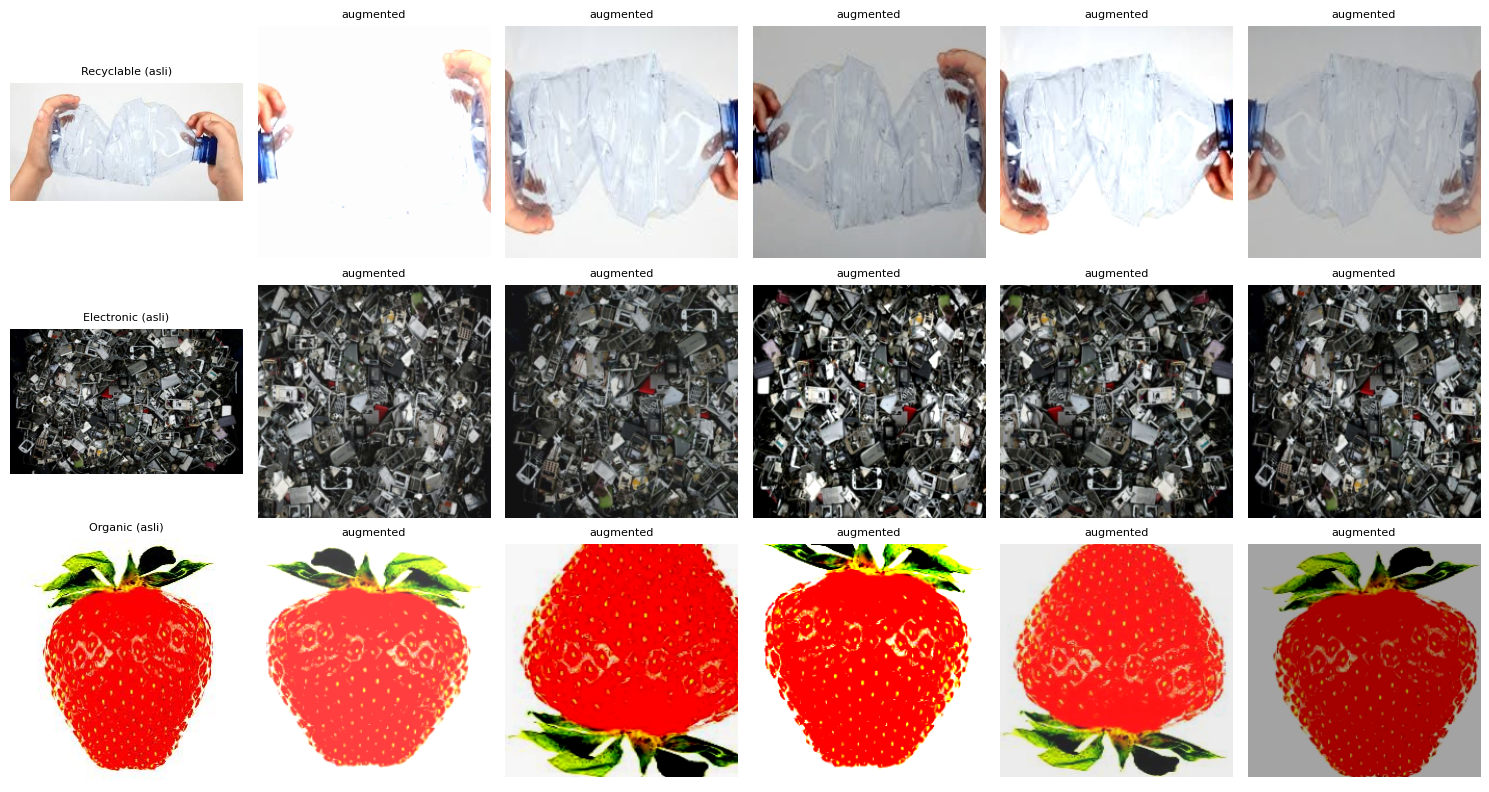

In [15]:
# Sanity check visual augmentasi: 1 gambar per kelas, 5 variasi augmented
viz_tf = transforms.Compose(train_transform.transforms[:-2])  # tanpa ToTensor/Normalize
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for i in range(CFG.NUM_CLASSES):
    row = train_df[train_df["label"] == i].iloc[0]
    img = ImageOps.exif_transpose(Image.open(row["path"])).convert("RGB")
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{row['class_name']} (asli)", fontsize=8)
    for j in range(1, 6):
        axes[i, j].imshow(viz_tf(img))
        axes[i, j].set_title("augmented", fontsize=8)
    for j in range(6):
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

In [16]:
class FocalLossWithSmoothing(nn.Module):
    """Pola ref/ver34_clean_end_to_end.ipynb, identik v1/v2/v3."""

    def __init__(self, num_classes, alpha, gamma, smoothing):
        super().__init__()
        self.gamma = gamma
        self.smoothing = smoothing
        self.num_classes = num_classes
        self.alpha = alpha

    def forward(self, inputs, targets):
        with torch.no_grad():
            true_dist = torch.zeros_like(inputs)
            true_dist.fill_(self.smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_p = F.log_softmax(inputs, dim=-1)
        p = log_p.exp()
        focal_weight = (1.0 - p).pow(self.gamma)
        focal_weight = focal_weight * self.alpha[targets].view(-1, 1)
        return (-focal_weight * true_dist * log_p).sum(dim=-1).mean()


def build_criterion(fold_train_df):
    counts = fold_train_df["label"].value_counts()
    weights = torch.tensor([1.0 / math.sqrt(counts.get(c, 1)) for c in range(CFG.NUM_CLASSES)],
                           dtype=torch.float32, device=DEVICE)
    weights /= weights.mean()
    return FocalLossWithSmoothing(CFG.NUM_CLASSES, alpha=weights, gamma=CFG.FOCAL_GAMMA,
                                  smoothing=CFG.LABEL_SMOOTHING), weights


def build_sampler(fold_train_df, seed):
    counts = fold_train_df["label"].value_counts().to_dict()
    sample_weights = fold_train_df["label"].map(lambda c: 1.0 / counts[c]).to_numpy(dtype=np.float64).copy()
    gen = torch.Generator()
    gen.manual_seed(seed)
    return WeightedRandomSampler(torch.DoubleTensor(sample_weights), num_samples=len(sample_weights),
                                 replacement=True, generator=gen)


def mixup_cutmix_batch(images, targets):
    """Mixup/CutMix DI GPU setelah batch tiba (nol beban CPU loader), identik v3.
    Return: images (mungkin dimodifikasi in-place untuk cutmix), dan mix_info=(y_a, y_b, lam) atau None."""
    if CFG.MIX_PROB <= 0 or float(torch.rand(())) > CFG.MIX_PROB or images.size(0) < 2:
        return images, None
    use_cutmix = float(torch.rand(())) < 0.5
    alpha = CFG.CUTMIX_ALPHA if use_cutmix else CFG.MIXUP_ALPHA
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(images.size(0), device=images.device)
    if use_cutmix:
        H, W = images.shape[-2:]
        r = math.sqrt(1.0 - lam)
        cw, ch = int(W * r), int(H * r)
        cx, cy = np.random.randint(W), np.random.randint(H)
        x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
        y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
        if x2 > x1 and y2 > y1:
            images[:, :, y1:y2, x1:x2] = images[perm, :, y1:y2, x1:x2]
            lam = 1.0 - ((x2 - x1) * (y2 - y1) / (W * H))
        else:
            return images, None
    else:
        images = lam * images + (1.0 - lam) * images[perm]
    return images, (targets, targets[perm], lam)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan: Backbone Beku + Head Terlatih <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Ini satu-satunya bagian yang berubah secara substantif dari v3. Setiap keputusan beserta sumbernya:

**1. Freeze total, permanen, di-assert.** Seluruh parameter yang bukan `head.*` disetel `requires_grad=False` saat model dibangun, dan tidak ada mekanisme unfreeze (v3 `FREEZE_BACKBONE_EPOCHS=1` + unfreeze dihapus). Sanity assert "0 parameter backbone trainable" mengikuti findit-v17 (`assert _unfrozen == 0`), dan guard "harus ada parameter trainable" mengikuti DSC0118 (`RuntimeError` bila list trainable kosong). Mengikuti pelajaran lessons.md 2026-07-16, keputusan mati ditulis sebagai assert (`CFG.FREEZE_BACKBONE` di-assert True), bukan saklar yang bisa dibalik diam-diam.

**2. Optimizer hanya menerima parameter trainable.** `AdamW([p for p in model.parameters() if p.requires_grad], lr=4e-4)`, pola persis notebook gemastik segmentation dan DSC0118. LR head **4e-4 = HEAD_LR v3** (tidak diganti): epoch 1 v3 juga backbone-beku dengan head LR 4e-4, jadi v4 secara harfiah adalah rezim epoch-1 v3 yang diteruskan sampai selesai. Angka ini sekaligus berada di tengah rentang referensi frozen: 2e-4 (template DINOv3 base), 3e-4 (findit-v17), 1e-3 (DSC0118). Scheduler tetap CosineAnnealing per epoch dan epoch budget tetap 15 + patience 3: konvergensi head yang lebih cepat ditangani early stopping, bukan dengan mengubah budget (menjaga ablation tetap satu variabel).

**3. `DROP_PATH_RATE` 0.1 -> 0.0.** Stochastic depth (Huang dkk., 2016) bekerja dengan menjatuhkan residual branch di dalam blok backbone selama training, regularisasi UNTUK BOBOT YANG SEDANG DIUPDATE. Dengan backbone beku, bobotnya tidak diupdate sama sekali; drop_path aktif hanya akan membuat "fitur beku" menjadi stokastik antar step tanpa ada yang bisa beradaptasi. Semua referensi frozen (findit-v17, DSC0118, kedua template) memperlakukan backbone sebagai feature extractor deterministik. Bonus penting: karena ConvNeXtV2 tidak punya BatchNorm (LayerNorm + GRN, berperilaku identik di train/eval) dan tanpa drop_path tidak ada lagi modul stokastik di backbone, `model.train()` aman dipakai apa adanya, tanpa perlu memaksa `backbone.eval()` terpisah.

**4. Head: MLP kecil `Linear(1024,512) -> GELU -> Dropout(0.3) -> Linear(512,3)`.** Saat backbone beku, head adalah satu-satunya kapasitas adaptif; linear tunggal 3K parameter adalah probe paling terkontrol tetapi juga plafon paling rendah. Preseden langsung: findit-v17 memakai persis pola MLP ini pada backbone fully-frozen; head-search ver34 juga memenangkan head yang lebih kaya dari linear tunggal; template DINOv3 menambah Dropout sebelum linear. Penjaga overfit head: Dropout 0.3, hidden kecil (512), early stopping, mixup. `head.norm` (LayerNorm bawaan timm sebelum fc) ikut terlatih karena memang bagian head. Toggle `CFG.HEAD_HIDDEN=0` mengembalikan linear probe murni untuk run pembanding.

**5. Konsekuensi komputasi.** Autograd berhenti di input head karena tidak ada parameter backbone yang butuh gradien: backward menjadi head-only (murah), aktivasi backbone tidak disimpan untuk backward (VRAM turun jauh), dan `state_dict` antar checkpoint hanya berbeda di head sehingga soup efektif meratakan head saja. Forward backbone tetap biaya penuh, jadi run tidak gratis, hanya jauh lebih ringan dari full fine-tune.

**6. Single-GPU tetap dipaksa.** `maybe_data_parallel` hardcode menolak DataParallel (leak RAM broadcast di T4x2, keputusan final v1); T4x2 terdeteksi 2 GPU pun notebook tetap memakai 1 GPU. `channels_last` aktif untuk conv net + AMP.

In [17]:
def build_model(pretrained=True):
    """ConvNeXtV2-Base dengan backbone BEKU dan head terlatih. Dipakai training DAN inference
    (satu sumber kebenaran arsitektur; v3 sempat menduplikasi konstruksi model di sel inference)."""
    assert CFG.FREEZE_BACKBONE, (
        "CFG.FREEZE_BACKBONE harus True: freeze adalah keputusan inti v4 (ablation vs v3). "
        "Kalau mau full fine-tune, itu notebook v3, bukan v4.")
    model = timm.create_model(CFG.MODEL_ID, pretrained=pretrained, num_classes=CFG.NUM_CLASSES,
                              drop_path_rate=CFG.DROP_PATH_RATE)
    n_param = sum(p.numel() for p in model.parameters()) / 1e6
    assert 60 < n_param < 110, f"Jumlah parameter {n_param:.1f}M tidak wajar untuk ConvNeXtV2-Base; cek CFG.MODEL_ID"

    # Struktur head timm ConvNeXt: model.head.(global_pool|norm|flatten|drop|fc). Fail-fast bila berubah.
    assert hasattr(model, "head") and hasattr(model.head, "fc") and isinstance(model.head.fc, nn.Linear), (
        "Struktur head timm tidak seperti yang diharapkan (model.head.fc bukan nn.Linear). "
        "Versi timm berubah? Periksa model.head sebelum lanjut.")
    if CFG.HEAD_HIDDEN > 0:
        in_features = model.head.fc.in_features
        model.head.fc = nn.Sequential(
            nn.Linear(in_features, CFG.HEAD_HIDDEN),
            nn.GELU(),
            nn.Dropout(CFG.HEAD_DROPOUT),
            nn.Linear(CFG.HEAD_HIDDEN, CFG.NUM_CLASSES),
        )

    # Freeze SETELAH operasi head: semua parameter non-head dibekukan permanen
    for n, p in model.named_parameters():
        if not n.startswith("head."):
            p.requires_grad = False
    return model


def assert_frozen(model):
    """Sanity keras sebelum optimizer dibuat (pola findit-v17 + DSC0118)."""
    bad = [n for n, p in model.named_parameters() if p.requires_grad and not n.startswith("head.")]
    assert not bad, f"Backbone tidak sepenuhnya beku, contoh parameter trainable: {bad[:5]}"
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n_trainable > 0, "Tidak ada parameter trainable sama sekali; head tidak terdeteksi dengan benar"
    return n_trainable


def build_optimizer(model):
    """AdamW SATU grup: hanya parameter head (requires_grad=True). LR = HEAD_LR v3."""
    assert_frozen(model)
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(trainable, lr=CFG.HEAD_LR, weight_decay=CFG.WEIGHT_DECAY)
    print(f"optimizer: AdamW head-only | lr={CFG.HEAD_LR:.0e} | "
          f"{sum(p.numel() for p in trainable) / 1e6:.3f}M param trainable")
    return opt


def maybe_data_parallel(model):
    """v4 SELALU single-GPU, termasuk di Kaggle T4x2 yang melaporkan 2 GPU.

    nn.DataParallel mem-broadcast parameter tiap step lewat host staging memory dan terbukti bocor
    RAM di T4x2 (keputusan final v1, dipertahankan v3/v4). Larangan di-hardcode; CFG.USE_DATA_PARALLEL
    dipertahankan sebagai dokumentasi keputusan dan di-assert supaya menyalakannya gagal keras.
    """
    assert not CFG.USE_DATA_PARALLEL, (
        "CFG.USE_DATA_PARALLEL harus False: DataParallel bocor RAM di T4x2 (keputusan final v1). "
        "v4 tidak menyediakan jalur multi-GPU.")
    if DEVICE.type == "cuda" and N_GPUS > 1:
        print(f"{N_GPUS} GPU terdeteksi; v4 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).",
              flush=True)
    return model


def to_device(model):
    model = model.to(DEVICE)
    if CFG.CHANNELS_LAST and DEVICE.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    return model


_m = build_model()
_total = sum(p.numel() for p in _m.parameters())
_trainable = assert_frozen(_m)
print(f"total params    : {_total / 1e6:.1f}M")
print(f"trainable (head): {_trainable / 1e6:.3f}M ({100.0 * _trainable / _total:.2f}% dari total)")
print(f"frozen (backbone): {(_total - _trainable) / 1e6:.1f}M")
print("head:", _m.head)
del _m

total params    : 88.2M
trainable (head): 0.528M (0.60% dari total)
frozen (backbone): 87.7M
head: NormMlpClassifierHead(
  (global_pool): SelectAdaptivePool2d(pool_type=avg, flatten=Identity())
  (norm): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (pre_logits): Identity()
  (drop): Dropout(p=0.0, inplace=False)
  (fc): Sequential(
    (0): Linear(in_features=1024, out_features=512, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=3, bias=True)
  )
)


> ### Insights
> Tiga hal yang layak diperhatikan dari angka parameter di atas:
> parameter trainable turun dari 87.7M (v3, full fine-tune) menjadi di bawah 1M (head saja), sekitar 0.6-0.7% dari total; ini reduksi kapasitas adaptif sekitar dua orde besaran, bentuk regularisasi paling keras yang bisa diberikan tanpa mengubah arsitektur.
> Karena checkpoint antar epoch hanya berbeda di head, greedy soup pada state_dict penuh secara matematis identik dengan soup pada head saja (rata-rata nilai yang sama = nilai itu sendiri); mekanisme soup v3 dipakai tanpa modifikasi.
> Kalau assert struktur head gagal di versi timm yang lebih baru, JANGAN dilonggarkan diam-diam; periksa `model.head` dan sesuaikan surgery secara eksplisit, karena salah menempel head = melatih probe di tempat yang salah tanpa error.

In [18]:
def run_epoch(model, loader, criterion=None, optimizer=None, scaler=None, use_tta=False, desc="",
              train_mix=False):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    losses, all_targets, all_preds, all_probs = [], [], [], []
    if is_train:
        optimizer.zero_grad(set_to_none=True)
    t_start = time.time()
    rss_start = rss_gb()
    progress = tqdm(loader, desc=desc or ("train" if is_train else "valid"), leave=False)
    for step, batch in enumerate(progress, start=1):
        images = batch["image"].to(DEVICE, non_blocking=True)
        if CFG.CHANNELS_LAST and DEVICE.type == "cuda":
            images = images.to(memory_format=torch.channels_last)
        targets = batch["target"].to(DEVICE, non_blocking=True) if "target" in batch else None
        mix_info = None
        if is_train and train_mix and targets is not None:
            images, mix_info = mixup_cutmix_batch(images, targets)
        amp_ctx = torch.amp.autocast("cuda", dtype=torch.float16) if DEVICE.type == "cuda" else nullcontext()
        with torch.set_grad_enabled(is_train), amp_ctx:
            logits = model(images)
            if use_tta and not is_train:
                logits = 0.5 * (logits + model(torch.flip(images, dims=[3])))
            if criterion is not None and targets is not None:
                if mix_info is not None:
                    y_a, y_b, lam = mix_info
                    loss = lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)
                else:
                    loss = criterion(logits, targets)
            else:
                loss = None
        if is_train:
            scaled = loss / CFG.GRAD_ACCUM_STEPS
            if scaler is not None:
                scaler.scale(scaled).backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    if CFG.GRAD_CLIP_NORM:
                        scaler.unscale_(optimizer)
                        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP_NORM)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
            else:
                scaled.backward()
                if step % CFG.GRAD_ACCUM_STEPS == 0 or step == len(loader):
                    if CFG.GRAD_CLIP_NORM:
                        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP_NORM)
                    optimizer.step()
                    optimizer.zero_grad(set_to_none=True)
        probs = torch.softmax(logits.float(), dim=1).detach().cpu().numpy()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(axis=1).tolist())
        if loss is not None:
            losses.append(loss.item())
            # catatan: pada batch ter-mix, target metrik memakai y asli (train F1 = indikator kasar saja)
            all_targets.extend(targets.cpu().numpy().tolist())
            progress.set_postfix(loss=f"{np.mean(losses):.4f}")
        if step % CFG.HEARTBEAT_EVERY_BATCH == 0 or step == len(loader):
            elapsed = time.time() - t_start
            pct = 100.0 * step / max(len(loader), 1)
            _rss_now = rss_gb()
            _vram = (f" | VRAM {torch.cuda.max_memory_allocated() / 1024 ** 3:.1f}GB"
                     if DEVICE.type == "cuda" else "")
            print(f"[hb] {desc or 'epoch'}: batch {step}/{len(loader)} ({pct:.0f}%) | "
                  f"{elapsed / step:.2f}s/iter | RSS {_rss_now:.1f}GB (delta {_rss_now - rss_start:+.1f}GB){_vram}",
                  flush=True)
            if WANDB_ENABLED and wandb.run is not None:
                wandb.log({"hb/pct": pct, "hb/sec_per_iter": elapsed / step, "hb/batch": step,
                           "hb/rss_gb": _rss_now})
    out = {"loss": float(np.mean(losses)) if losses else float("nan"),
           "preds": np.array(all_preds),
           "probs": np.concatenate(all_probs) if all_probs else None}
    if all_targets:
        out["targets"] = np.array(all_targets)
        out["macro_f1"] = float(f1_score(out["targets"], out["preds"], average="macro"))
        out["per_class_f1"] = f1_score(out["targets"], out["preds"], average=None,
                                       labels=list(range(CFG.NUM_CLASSES)))
    return out

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Training, Soup, dan Ablation TTA <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Loop training identik v3 dengan dua perbedaan: panggilan unfreeze per epoch dihapus (backbone beku permanen sejak `build_model`) dan `assert_frozen` dijalankan tiap fold sebelum optimizer dibuat.

**Mekanisme soup per fold** (arXiv 2603.02181, greedy, tetap satu model):
1. Tiap akhir epoch, state model (CPU copy) masuk buffer top-K (K=5) terurut val macro F1 (dengan TTA, konsisten metrik early stopping).
2. Setelah fold selesai: mulai dari checkpoint terbaik, kandidat lain dicoba satu per satu; rata-rata bobot dipertahankan hanya bila val macro F1 (tanpa TTA, konsisten antar trial) membaik.
3. Pemenang fold = soup atau best-single; **ablation TTA dijalankan pada pemenang** (TTA tidak diasumsikan membantu; wajib divalidasi per fold, arXiv 2604.09697). TTA yang dipakai hflip 2-view DENGAN view original di dalamnya, sesuai rekomendasi paper yang sama; hflip juga transformasi yang ada di distribusi training.

> ### Insights
> Cara membaca log epoch v4 supaya tidak salah tafsir:
> `train_f1` akan tampak jauh di bawah `val_f1` seperti di v3; itu artefak metrik saat mixup aktif (F1 train dihitung terhadap label asli pada batch campuran), BUKAN indikator underfit/overfit yang bisa dibaca mentah.
> Sinyal yang benar untuk dipantau: `val_f1` per epoch (kecepatan konvergensi head), F1 per kelas (apakah Recyclable/Organic tertinggal), dan perbandingan no-TTA vs TTA per fold.
> Kalau `val_f1` sudah datar sejak epoch awal, itu perilaku wajar rezim frozen-head (referensi template DINOv3 memakai 8 epoch, DSC0118 10 epoch); early stopping patience 3 yang akan memangkasnya.

In [19]:
def state_to_cpu(sd):
    return {k: v.detach().to("cpu", copy=True) for k, v in sd.items()}


def average_states(states):
    """Rata-rata parameter float; buffer non-float diambil dari state pertama."""
    out = {}
    for k, v in states[0].items():
        if torch.is_floating_point(v):
            acc = v.to(torch.float64).clone()
            for s in states[1:]:
                acc += s[k].to(torch.float64)
            out[k] = (acc / len(states)).to(v.dtype)
        else:
            out[k] = v.clone()
    return out


fold_summaries = []
history_rows = []
oof_probs = np.full((len(train_df), CFG.NUM_CLASSES), np.nan)

for fold in CFG.TRAIN_FOLDS:
    print(f"\n===== FOLD {fold} =====")
    seed_everything(CFG.SEED + fold, deterministic=CFG.CUDNN_DETERMINISTIC)
    tr_df = train_df[train_df["fold"] != fold].reset_index(drop=True)
    va_df = train_df[train_df["fold"] == fold].reset_index(drop=True)
    va_positions = np.where((train_df["fold"] == fold).to_numpy())[0]

    dl_kwargs = dict(num_workers=CFG.NUM_WORKERS, pin_memory=PIN_MEMORY,
                     persistent_workers=CFG.NUM_WORKERS > 0,
                     prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                     worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
    train_loader = DataLoader(WasteDataset(tr_df, train_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                              batch_size=CFG.BATCH_SIZE,
                              sampler=build_sampler(tr_df, CFG.SEED + fold), shuffle=False, **dl_kwargs)
    val_loader = DataLoader(WasteDataset(va_df, eval_transform, max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2, shuffle=False, **dl_kwargs)

    model = maybe_data_parallel(to_device(build_model()))
    n_trainable_fold = assert_frozen(model)
    print(f"fold {fold}: backbone beku terverifikasi | {n_trainable_fold / 1e6:.3f}M param head trainable")
    criterion, class_alpha = build_criterion(tr_df)
    print("alpha per kelas:", {CFG.LABEL_NAMES[i]: round(float(a), 3) for i, a in enumerate(class_alpha)})
    if WANDB_ENABLED:
        wandb.init(project=WANDB_PROJECT,
                   name=f"{CFG.RUN_NAME}-fold{fold}" + ("-smoke" if CFG.SMOKE_TEST else ""),
                   config={"model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE, "batch_size": CFG.BATCH_SIZE,
                           "grad_accum": CFG.GRAD_ACCUM_STEPS, "epochs": CFG.EPOCHS,
                           "frozen_backbone": CFG.FREEZE_BACKBONE, "head_hidden": CFG.HEAD_HIDDEN,
                           "head_dropout": CFG.HEAD_DROPOUT, "head_lr": CFG.HEAD_LR,
                           "drop_path_rate": CFG.DROP_PATH_RATE, "use_vflip": CFG.USE_VFLIP,
                           "mix_prob": CFG.MIX_PROB, "soup_topk": CFG.SOUP_TOPK, "fold": fold,
                           "smoke_test": CFG.SMOKE_TEST},
                   reinit=True)
    optimizer = build_optimizer(model)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    scaler = torch.amp.GradScaler("cuda") if DEVICE.type == "cuda" else None

    best = {"macro_f1": -1.0, "epoch": -1}
    soup_pool = []  # top-K state per fold: dict(f1, epoch, state[cpu])
    no_improve = 0
    ckpt_path = CFG.EXP_DIR / f"{'smoke_' if CFG.SMOKE_TEST else ''}fold{fold}_best.pt"
    for epoch in range(1, CFG.EPOCHS + 1):
        tr_m = run_epoch(model, train_loader, criterion, optimizer, scaler,
                         desc=f"f{fold} e{epoch} train", train_mix=True)
        va_m = run_epoch(model, val_loader, criterion, use_tta=CFG.USE_VAL_TTA, desc=f"f{fold} e{epoch} valid")
        scheduler.step()
        pc = {f"val_f1_{CFG.LABEL_NAMES[i]}": float(va_m["per_class_f1"][i]) for i in range(CFG.NUM_CLASSES)}
        history_rows.append({"fold": fold, "epoch": epoch,
                             "train_loss": tr_m["loss"], "train_macro_f1": tr_m["macro_f1"],
                             "val_loss": va_m["loss"], "val_macro_f1": va_m["macro_f1"], **pc})
        pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
        print(f"epoch {epoch:02d} | train_f1={tr_m['macro_f1']:.4f} | val_f1={va_m['macro_f1']:.4f} | "
              f"val_loss={va_m['loss']:.4f} | per-kelas: "
              + " ".join(f"{CFG.LABEL_NAMES[i][:1]}={va_m['per_class_f1'][i]:.4f}" for i in range(CFG.NUM_CLASSES)),
              flush=True)
        if WANDB_ENABLED and wandb.run is not None:
            wandb.log({"epoch": epoch, "train/loss": tr_m["loss"], "train/macro_f1": tr_m["macro_f1"],
                       "val/loss": va_m["loss"], "val/macro_f1": va_m["macro_f1"], **{f"val/{k}": v for k, v in pc.items()}})

        soup_pool.append({"f1": va_m["macro_f1"], "epoch": epoch, "state": state_to_cpu(model.state_dict())})
        soup_pool = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)[:CFG.SOUP_TOPK]

        if va_m["macro_f1"] > best["macro_f1"]:
            best = {"macro_f1": va_m["macro_f1"], "epoch": epoch}
            no_improve = 0
            torch.save({"state_dict": soup_pool[0]["state"] if soup_pool[0]["epoch"] == epoch else state_to_cpu(model.state_dict()),
                        "model_id": CFG.MODEL_ID, "img_size": CFG.IMG_SIZE,
                        "head_hidden": CFG.HEAD_HIDDEN, "head_dropout": CFG.HEAD_DROPOUT,
                        "drop_path_rate": CFG.DROP_PATH_RATE, "frozen_backbone": True,
                        "fold": fold, "best_epoch": epoch, "val_macro_f1": va_m["macro_f1"],
                        "mean": MEAN, "std": STD, "smoke": CFG.SMOKE_TEST, "soup_members": [epoch]}, ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CFG.EARLY_STOPPING_PATIENCE:
                print(f"early stopping di epoch {epoch}")
                break

    # ---- greedy soup: seleksi subset kandidat yang rata-rata bobotnya menaikkan val F1 (tanpa TTA) ----
    cands = sorted(soup_pool, key=lambda d: d["f1"], reverse=True)
    model.load_state_dict(cands[0]["state"])
    base_eval = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} soup base")
    best_single_f1_no_tta = base_eval["macro_f1"]
    selected = [cands[0]]
    soup_f1_no_tta = best_single_f1_no_tta
    if CFG.USE_GREEDY_SOUP and len(cands) > 1:
        for cand in cands[1:]:
            trial_state = average_states([c["state"] for c in selected] + [cand["state"]])
            model.load_state_dict(trial_state)
            trial_f1 = run_epoch(model, val_loader, criterion, use_tta=False,
                                 desc=f"f{fold} soup try+e{cand['epoch']}")["macro_f1"]
            if trial_f1 > soup_f1_no_tta + 1e-6:
                selected.append(cand)
                soup_f1_no_tta = trial_f1
                print(f"soup: +epoch {cand['epoch']} DITERIMA (val_f1 {trial_f1:.4f})", flush=True)
            else:
                print(f"soup: +epoch {cand['epoch']} ditolak (val_f1 {trial_f1:.4f} <= {soup_f1_no_tta:.4f})", flush=True)
    soup_members = sorted(c["epoch"] for c in selected)
    winner_state = average_states([c["state"] for c in selected]) if len(selected) > 1 else cands[0]["state"]
    winner_tag = f"soup(e{soup_members})" if len(selected) > 1 else f"single(e{cands[0]['epoch']})"
    print(f"fold {fold} pemenang: {winner_tag} | best-single no-TTA={best_single_f1_no_tta:.4f} | soup no-TTA={soup_f1_no_tta:.4f}")

    model.load_state_dict(winner_state)
    # Ablation TTA pada pemenang (TTA tidak diasumsikan membantu; divalidasi per fold, arXiv 2604.09697)
    val_no_tta = run_epoch(model, val_loader, criterion, use_tta=False, desc=f"f{fold} winner tanpa-TTA")
    val_tta = run_epoch(model, val_loader, criterion, use_tta=True, desc=f"f{fold} winner TTA")
    print(f"fold {fold} ablation TTA: tanpa-TTA={val_no_tta['macro_f1']:.4f} | TTA={val_tta['macro_f1']:.4f}")
    final_val = val_tta if CFG.USE_VAL_TTA else val_no_tta
    oof_probs[va_positions] = final_val["probs"]
    per_class = final_val["per_class_f1"]

    torch.save({"state_dict": state_to_cpu(model.state_dict()), "model_id": CFG.MODEL_ID,
                "img_size": CFG.IMG_SIZE,
                "head_hidden": CFG.HEAD_HIDDEN, "head_dropout": CFG.HEAD_DROPOUT,
                "drop_path_rate": CFG.DROP_PATH_RATE, "frozen_backbone": True,
                "fold": fold, "best_epoch": best["epoch"],
                "val_macro_f1": final_val["macro_f1"], "mean": MEAN, "std": STD,
                "smoke": CFG.SMOKE_TEST, "soup_members": soup_members}, ckpt_path)
    fold_summaries.append({"fold": fold, "best_epoch": best["epoch"], "winner": winner_tag,
                           "n_soup_members": len(selected),
                           "val_macro_f1": final_val["macro_f1"],
                           "val_macro_f1_no_tta": val_no_tta["macro_f1"],
                           "val_macro_f1_tta": val_tta["macro_f1"],
                           "best_single_no_tta": best_single_f1_no_tta,
                           "soup_no_tta": soup_f1_no_tta,
                           **{f"f1_{CFG.LABEL_NAMES[i]}": float(per_class[i]) for i in range(CFG.NUM_CLASSES)}})
    pd.DataFrame(fold_summaries).to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
    print(f"fold {fold}: best_epoch={best['epoch']} val_macro_f1={final_val['macro_f1']:.4f} | ckpt: {ckpt_path.name}")
    if WANDB_ENABLED and wandb.run is not None:
        wandb.log({"ablation/val_macro_f1_no_tta": val_no_tta["macro_f1"],
                   "ablation/val_macro_f1_tta": val_tta["macro_f1"],
                   "soup/n_members": len(selected), "soup/gain_no_tta": soup_f1_no_tta - best_single_f1_no_tta})
        wandb.finish()
    del model, soup_pool, cands, selected, winner_state
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

fold_summary_df = pd.DataFrame(fold_summaries)
pd.DataFrame(history_rows).to_csv(CFG.EXP_DIR / "history.csv", index=False)
fold_summary_df.to_csv(CFG.EXP_DIR / "fold_summary.csv", index=False)
display(fold_summary_df)


===== FOLD 0 =====


2 GPU terdeteksi; v4 sengaja memakai 1 GPU saja (DataParallel dilarang: leak T4x2).


fold 0: backbone beku terverifikasi | 0.528M param head trainable
alpha per kelas: {'Recyclable': 0.86, 'Electronic': 1.372, 'Organic': 0.768}
optimizer: AdamW head-only | lr=4e-04 | 0.528M param trainable


f0 e1 train:   0%|          | 0/662 [00:00<?, ?it/s]

[hb] f0 e1 train: batch 50/662 (8%) | 0.41s/iter | RSS 2.2GB (delta +0.6GB) | VRAM 1.0GB


...

[hb] f2 e8 valid: batch 83/83 (100%) | 0.83s/iter | RSS 5.3GB (delta +0.0GB) | VRAM 1.7GB


epoch 08 | train_f1=0.8611 | val_f1=0.9722 | val_loss=0.1086 | per-kelas: R=0.9656 E=0.9768 O=0.9741


early stopping di epoch 8


f2 soup base:   0%|          | 0/83 [00:00<?, ?it/s]

[hb] f2 soup base: batch 50/83 (60%) | 0.44s/iter | RSS 5.4GB (delta +0.0GB) | VRAM 1.7GB


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Evaluasi dan Perbandingan dengan v3 <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Pembanding utama adalah **v3 pada data dan fold yang sama**: OOF pooled 0.9844 (train-side) dan LB 98,0473 (konteks, bukan acuan seleksi). Cara membaca hasil v4:

- **OOF v4 vs 0.9844**: mengukur berapa "harga" yang dibayar (atau tidak) karena membekukan backbone, apples-to-apples per fold.
- **Yang tidak bisa dijawab dari OOF**: apakah gap OOF-LB menyempit. Itu hanya terjawab kalau v4 disubmit, dan keputusan submit ada di user (sisa 2 jatah). Notebook ini tidak membuat klaim skor.
- Dasar keputusan selalu OOF/val train-side, tidak pernah leaderboard-probing atau data test (juknis SS5).

In [ ]:
oof_mask = ~np.isnan(oof_probs).any(axis=1)
scope = "OOF pooled" if len(CFG.TRAIN_FOLDS) == CFG.N_FOLDS else f"val fold {CFG.TRAIN_FOLDS}"
print(f"Evaluasi tersedia untuk {int(oof_mask.sum())}/{len(train_df)} baris ({scope})")
oof_pred = oof_probs[oof_mask].argmax(axis=1)
oof_true = train_df.loc[oof_mask, "label"].to_numpy()

oof_macro_f1 = f1_score(oof_true, oof_pred, average="macro")
oof_per_class = f1_score(oof_true, oof_pred, average=None, labels=list(range(CFG.NUM_CLASSES)))
print(f"\nMacro F1 v4 ({scope}, seleksi TTA={CFG.USE_VAL_TTA}): {oof_macro_f1:.4f}")
print(f"Referensi v3 (data & fold sama)  : OOF pooled {CFG.REF_V3_OOF_POOLED:.4f} "
      f"(selisih v4-v3: {oof_macro_f1 - CFG.REF_V3_OOF_POOLED:+.4f})")
print(f"Konteks LB v3 (submission #1)    : {CFG.REF_V3_LB:.4f} pada skala 0-100 "
      f"(OOF v3 meleset -0.39 poin terhadap LB; angka LB v4 baru ada kalau disubmit)")
print()
print(classification_report(oof_true, oof_pred,
                            labels=list(range(CFG.NUM_CLASSES)),
                            target_names=[CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)], digits=4))

cm = confusion_matrix(oof_true, oof_pred, labels=list(range(CFG.NUM_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
tick_names = [CFG.LABEL_NAMES[i] for i in range(CFG.NUM_CLASSES)]
ax.set_xticks(range(CFG.NUM_CLASSES), tick_names)
ax.set_yticks(range(CFG.NUM_CLASSES), tick_names)
for i in range(CFG.NUM_CLASSES):
    for j in range(CFG.NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]:.3f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion matrix v4 freeze ({scope}, row-normalized)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

oof_out = train_df.loc[oof_mask, ["relpath", "class_name", "label", "fold"]].copy()
oof_out["pred"] = oof_pred
for i in range(CFG.NUM_CLASSES):
    oof_out[f"prob_{i}"] = oof_probs[oof_mask, i]
oof_out.to_csv(CFG.EXP_DIR / "oof_predictions.csv", index=False)
print("Prediksi val disimpan:", CFG.EXP_DIR / "oof_predictions.csv")

In [ ]:
# Kurva training: loss dan macro F1 per epoch (+ F1 per kelas val)
hist = pd.DataFrame(history_rows)
if len(hist):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for f, g in hist.groupby("fold"):
        axes[0].plot(g["epoch"], g["train_loss"], "--", label=f"train f{f}")
        axes[0].plot(g["epoch"], g["val_loss"], "-", label=f"val f{f}")
        axes[1].plot(g["epoch"], g["train_macro_f1"], "--", label=f"train f{f}")
        axes[1].plot(g["epoch"], g["val_macro_f1"], "-", label=f"val f{f}")
        for i in range(CFG.NUM_CLASSES):
            axes[2].plot(g["epoch"], g[f"val_f1_{CFG.LABEL_NAMES[i]}"], "-",
                         label=f"{CFG.LABEL_NAMES[i]} f{f}")
    for ax, ttl in zip(axes, ["Loss", "Macro F1", "Val F1 per kelas"]):
        ax.set_xlabel("epoch")
        ax.set_title(ttl)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
# Catat hasil ke experiments/EXPERIMENTS_LOG.md (append-only, entry lama tidak boleh ditimpa)
NOTES = ("v4: ConvNeXtV2-Base fcmae_ft_in22k_in1k FREEZE-BACKBONE penuh (hanya head dilatih) 224px, "
         "ablation terkontrol terhadap v3 full fine-tune: data ronde-1 relabel identik submission #1 "
         "(guard versi data aktif), fold identik (prosedur+seed sama), augmentasi/loss/sampler/soup/TTA "
         f"identik v3. Perubahan karena freeze: drop_path 0.1->0.0, head MLP hidden={CFG.HEAD_HIDDEN} "
         f"dropout={CFG.HEAD_DROPOUT} (0=linear probe), optimizer AdamW head-only lr={CFG.HEAD_LR}, "
         f"epochs {CFG.EPOCHS} patience {CFG.EARLY_STOPPING_PATIENCE}, "
         f"mixup/cutmix p={CFG.MIX_PROB}, grad clip {CFG.GRAD_CLIP_NORM}, "
         f"greedy soup top-{CFG.SOUP_TOPK}, batch {CFG.BATCH_SIZE}x{CFG.GRAD_ACCUM_STEPS}.")

_soup_desc = ", ".join(f"fold{r.fold}: {r.winner} (single {r.best_single_no_tta:.4f} -> soup {r.soup_no_tta:.4f})"
                       for r in fold_summary_df.itertuples())
_dev_desc = (torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else str(DEVICE))
entry = f"""
## {CFG.RUN_NAME} - {date.today().isoformat()}

- Backbone            : {CFG.MODEL_ID} (timm), BACKBONE BEKU + head MLP({CFG.HEAD_HIDDEN}) terlatih, img {CFG.IMG_SIZE} | device: {_dev_desc}
- Data                : {len(train_df)} gambar train ronde-1 relabel identik submission #1 (guard {CFG.EXPECTED_CLASS_COUNTS}) | fold dilatih: {CFG.TRAIN_FOLDS} dari {CFG.N_FOLDS} (fold identik v3)
- Macro F1 per fold   : {", ".join(f"fold{r.fold}={r.val_macro_f1:.4f}" for r in fold_summary_df.itertuples())}
- TTA ablation (val)  : {", ".join(f"fold{r.fold}: tanpa-TTA={r.val_macro_f1_no_tta:.4f} / TTA={r.val_macro_f1_tta:.4f}" for r in fold_summary_df.itertuples())}
- Soup per fold       : {_soup_desc}
- Referensi           : v3 OOF pooled {CFG.REF_V3_OOF_POOLED:.4f} (data & fold sama); LB v3 {CFG.REF_V3_LB:.4f} (selisih OOF-LB v3 = -0.39, konteks utama eksperimen ini)
- Per-class F1        : {", ".join(f"{CFG.LABEL_NAMES[i]}={oof_per_class[i]:.4f}" for i in range(CFG.NUM_CLASSES))}
- Catatan             : {NOTES}
"""
print(entry)
if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: entry TIDAK ditulis ke log (bukan hasil eksperimen valid).")
else:
    CFG.LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
    with open(CFG.LOG_PATH, "a", encoding="utf-8") as f:
        f.write(entry)
    print(">> Entry ditambahkan (append) ke", CFG.LOG_PATH)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submission <a name="10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Aturan (juknis SS4-SS5): data test **hanya** untuk prediksi akhir; kolom `id,predicted`; kode 0/1/2; urutan id persis template. Nama file memakai **kode kelompok**: `submission_SD2026040000412.csv` (konfirmasi panitia).

**Exact match test->train** (identik v1/v2/v3): file test yang byte-identik dengan file train memakai label train langsung; legal karena murni kesamaan internal dataset kompetisi, dan label yang dipakai adalah label pasca-relabel ronde-1. Near-duplicate yang bukan exact TIDAK dipakai.

Prediksi model: mean softmax semua checkpoint fold + TTA hflip (konsisten dengan seleksi val). Rekonstruksi model memakai `build_model` yang sama dengan training (satu sumber kebenaran arsitektur: surgery head + freeze diterapkan identik), lalu metadata checkpoint di-assert supaya head yang dimuat cocok.

In [ ]:
ckpt_prefix = "smoke_" if CFG.SMOKE_TEST else ""
ckpt_paths = sorted(CFG.EXP_DIR.glob(f"{ckpt_prefix}fold*_best.pt"))
if not CFG.SMOKE_TEST:
    ckpt_paths = [p for p in ckpt_paths if not p.name.startswith("smoke_")]
assert ckpt_paths, "Tidak ada checkpoint fold, jalankan training dulu"
print("Checkpoint dipakai:", [p.name for p in ckpt_paths])
if len(ckpt_paths) < CFG.N_FOLDS:
    print(f"PERINGATAN: baru {len(ckpt_paths)}/{CFG.N_FOLDS} fold; submission final sebaiknya memakai semua fold.")

test_infer_df = pd.DataFrame({"id": TEMPLATE_ID_ORDER})
test_infer_df["path"] = test_infer_df["id"].map(lambda i: str(test_id_to_path[i]))
assert test_infer_df["path"].notna().all()
if CFG.SMOKE_TEST:
    test_infer_df = test_infer_df.head(CFG.SMOKE_TEST_IMAGES)
    print(f"SMOKE_TEST: inference hanya {len(test_infer_df)} gambar test pertama (cek pipeline).")

# Exact match test->train via sha256 (train_df sudah unik per sha, mixed-label sudah dikeluarkan)
hash_to_label = train_df.set_index("sha256")["label"].to_dict()
relpath_to_hash = test_scan.set_index("relpath")["sha256"].to_dict()
test_infer_df["sha256"] = [relpath_to_hash.get(str(Path(p).relative_to(CFG.DATA_ROOT)))
                           for p in test_infer_df["path"]]
test_infer_df["match_label"] = test_infer_df["sha256"].map(hash_to_label)
matched_mask = test_infer_df["match_label"].notna().to_numpy()
print(f"Exact match test->train: {int(matched_mask.sum())}/{len(test_infer_df)} baris memakai label train langsung")

preds = np.full(len(test_infer_df), -1, dtype=int)
preds[matched_mask] = test_infer_df.loc[matched_mask, "match_label"].astype(int).to_numpy()

unmatched_df = test_infer_df[~matched_mask].reset_index(drop=True)


def infer_mean_probs(ckpt_list, infer_df):
    """Mean softmax lintas checkpoint fold (satu arsitektur); transform eval dari metadata checkpoint."""
    total = np.zeros((len(infer_df), CFG.NUM_CLASSES))
    for cp in ckpt_list:
        ckpt = torch.load(cp, map_location="cpu", weights_only=False)
        assert ckpt["model_id"] == CFG.MODEL_ID, f"{cp}: model_id {ckpt['model_id']} != {CFG.MODEL_ID}"
        assert CFG.SMOKE_TEST or not ckpt.get("smoke"), f"{Path(cp).name} berasal dari smoke run"
        assert int(ckpt.get("head_hidden", -1)) == CFG.HEAD_HIDDEN, (
            f"{Path(cp).name}: head_hidden checkpoint = {ckpt.get('head_hidden')} != CFG {CFG.HEAD_HIDDEN}; "
            "checkpoint berasal dari konfigurasi head lain, jangan dicampur.")
        assert ckpt.get("frozen_backbone", False), f"{Path(cp).name}: bukan checkpoint freeze-backbone v4"
        _, tf_eval = build_transforms(ckpt["img_size"], tuple(ckpt["mean"]), tuple(ckpt["std"]))
        loader = DataLoader(WasteDataset(infer_df, tf_eval, with_target=False, safe_mode=True,
                                         img_size=ckpt["img_size"], max_decode_side=CFG.MAX_DECODE_SIDE),
                            batch_size=CFG.BATCH_SIZE * 2, shuffle=False, num_workers=CFG.NUM_WORKERS,
                            pin_memory=PIN_MEMORY,
                            prefetch_factor=2 if CFG.NUM_WORKERS > 0 else None,
                            worker_init_fn=worker_init_fn if CFG.NUM_WORKERS > 0 else None)
        model = build_model(pretrained=False)
        model.load_state_dict(ckpt["state_dict"])
        model = maybe_data_parallel(to_device(model))
        out = run_epoch(model, loader, use_tta=CFG.USE_VAL_TTA, desc=f"infer {Path(cp).stem}")
        total += out["probs"] / len(ckpt_list)
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return total


if len(unmatched_df):
    final_probs = infer_mean_probs(ckpt_paths, unmatched_df)
    preds[~matched_mask] = final_probs.argmax(axis=1).astype(int)

assert (preds >= 0).all()
test_infer_df["predicted"] = preds
print("\nDistribusi prediksi:")
print(test_infer_df["predicted"].value_counts().rename(index=CFG.LABEL_NAMES).to_string())

In [ ]:
submission_df = test_infer_df[["id", "predicted"]].copy()

# Verifikasi keras terhadap template SEBELUM menyimpan (juknis SS4: format & urutan wajib persis)
ref = template_df.head(len(submission_df)) if CFG.SMOKE_TEST else template_df
assert list(submission_df.columns) == ["id", "predicted"], "Nama/urutan kolom tidak sesuai template"
assert len(submission_df) == len(ref), f"Jumlah baris {len(submission_df)} != template {len(ref)}"
assert (submission_df["id"].to_numpy() == ref["id"].to_numpy()).all(), "Urutan id TIDAK sama dengan template!"
assert submission_df["predicted"].isin([0, 1, 2]).all(), "predicted harus kode numerik 0/1/2"
assert submission_df["predicted"].notna().all()
print("Semua verifikasi format & urutan id LULUS.")

if CFG.SMOKE_TEST:
    print(">> SMOKE_TEST aktif: file submission TIDAK disimpan. Jalankan full run untuk membuat submission.")
else:
    sub_path = CFG.SUBMISSION_DIR / f"submission_{CFG.GROUP_CODE}.csv"
    submission_df.to_csv(sub_path, index=False)
    submission_df.to_csv(CFG.EXP_DIR / sub_path.name, index=False)  # arsip per eksperimen
    print("Submission disimpan:", sub_path)
    print("(nama file memakai KODE KELOMPOK sesuai konfirmasi panitia, bukan nama tim)")
    comp = pd.DataFrame({
        "pred_test_%": (100 * submission_df["predicted"].value_counts(normalize=True)).round(2),
        "train_%": (100 * train_df["label"].value_counts(normalize=True)).round(2),
    }).rename(index=CFG.LABEL_NAMES)
    print("\nDistribusi prediksi test vs train (sanity check):")
    display(comp)
    print("INGAT: sisa 2 jatah submission dari 3; keputusan submit oleh user, berbasis OOF v4 vs v3")
    print("plus konteks selisih OOF-LB v3 (-0.39). File ini kandidat, bukan keputusan.")

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Error dan Grad-CAM <a name="11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Dua lapis analisis, dua-duanya murni train-side (val/OOF), tidak pernah menyentuh test:

1. **Top error by margin** (pola v1/v2/v3): baris val dengan `p_pred - p_label` terbesar; kandidat antrean review label ronde berikutnya (tidak ada relabel otomatis, keputusan manusia).
2. **Grad-CAM** (motivasi arXiv 2505.16513: model sortir cenderung belajar bentuk/warna/background, bukan material): pada error Recyclable vs Organic, cek apakah model menatap objek atau background. Untuk v4 ada nilai diagnostik ekstra: karena backbone beku, heatmap memperlihatkan ke mana fitur ImageNet murni menaruh perhatian, tanpa adaptasi domain.

Catatan implementasi penting (beda dari v3): pada model dengan seluruh backbone `requires_grad=False`, autograd tidak membangun graph melewati backbone, sehingga backward hook Grad-CAM pada `stages[-1]` **tidak akan pernah terpanggil**. Fix: input tensor disetel `requires_grad_(True)` supaya graph tetap terbentuk sampai piksel dan gradien mengalir melewati stage yang di-hook.

In [ ]:
err = oof_out[oof_out["pred"] != oof_out["label"]].copy()
if err.empty:
    print("Tidak ada error val (subset smoke terlalu kecil / hasil sempurna).")
else:
    probs_arr = err[[f"prob_{i}" for i in range(CFG.NUM_CLASSES)]].to_numpy()
    err["p_pred"] = probs_arr[np.arange(len(err)), err["pred"].to_numpy()]
    err["p_label"] = probs_arr[np.arange(len(err)), err["label"].to_numpy()]
    err["margin"] = err["p_pred"] - err["p_label"]
    err = err.sort_values("margin", ascending=False)
    print(f"Total error val: {len(err)} baris")
    print("\nPasangan (true -> pred) terbanyak:")
    print(err.groupby(["class_name", "pred"]).size().rename("n").reset_index()
          .assign(pred_name=lambda d: d["pred"].map(CFG.LABEL_NAMES))
          .sort_values("n", ascending=False).head(6).to_string(index=False))
    ro_mask = ((err["label"] == 0) & (err["pred"] == 2)) | ((err["label"] == 2) & (err["pred"] == 0))
    print(f"\nError Recyclable<->Organic: {int(ro_mask.sum())}/{len(err)} "
          f"({100 * ro_mask.mean():.1f}%; pembanding v2 di data asli: 84.5%)")
    err.head(200).to_csv(CFG.EXP_DIR / "oof_top_errors.csv", index=False)
    print("Top error disimpan:", CFG.EXP_DIR / "oof_top_errors.csv (input antrean review label ronde berikutnya)")

    n_show = min(18, len(err))
    path_by_relpath = train_df.set_index("relpath")["path"].to_dict()
    fig, axes = plt.subplots(3, 6, figsize=(16, 9))
    for ax, (_, r) in zip(axes.flat, err.head(n_show).iterrows()):
        try:
            img = Image.open(path_by_relpath[r["relpath"]])
            img.draft("RGB", (512, 512))
            ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
        except Exception:
            pass
        ax.set_title(f"{r['class_name']} -> {CFG.LABEL_NAMES[int(r['pred'])]}\nmargin {r['margin']:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[n_show:]:
        ax.axis("off")
    plt.suptitle("Error val dengan keyakinan tertinggi (kandidat review label manual)")
    plt.tight_layout()
    plt.show()

In [ ]:
# Grad-CAM pada error Recyclable<->Organic teratas: model menatap objek atau background?
def grad_cam(model, pil_img, target_class):
    """Grad-CAM standar pada stage terakhir ConvNeXtV2 (aktivasi spasial 7x7). fp32, tanpa autocast.

    Khusus model frozen: input WAJIB requires_grad_(True). Tanpa itu tidak ada satu pun tensor di
    backbone yang butuh gradien, graph tidak dibangun, dan backward hook tidak pernah terpanggil."""
    model.eval()
    acts, grads = [], []
    layer = model.stages[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: acts.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    try:
        x = eval_transform(pil_img).unsqueeze(0).to(DEVICE).requires_grad_(True)
        logits = model(x)
        model.zero_grad(set_to_none=True)
        logits[0, target_class].backward()
    finally:
        h1.remove()
        h2.remove()
    assert acts and grads, "Grad-CAM: hook tidak menangkap aktivasi/gradien; cek requires_grad input"
    a, g = acts[0][0].detach(), grads[0][0].detach()
    w = g.mean(dim=(1, 2), keepdim=True)
    cam = torch.relu((w * a).sum(0)).float().cpu().numpy()
    cam = cam / (cam.max() + 1e-8)
    return np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((CFG.IMG_SIZE, CFG.IMG_SIZE),
                                                                          Image.Resampling.BILINEAR)) / 255.0


if not err.empty:
    ro_err = err[ro_mask].head(6)
    if ro_err.empty:
        ro_err = err.head(6)
        print("Tidak ada error R<->O; Grad-CAM memakai top error umum.")
    ckpt = torch.load(ckpt_paths[0], map_location="cpu", weights_only=False)
    cam_model = build_model(pretrained=False)
    cam_model.load_state_dict(ckpt["state_dict"])
    cam_model = to_device(cam_model)

    fig, axes = plt.subplots(2, len(ro_err), figsize=(2.8 * len(ro_err), 6), squeeze=False)
    disp_tf = transforms.Compose([transforms.Resize(int(CFG.IMG_SIZE * 1.14)),
                                  transforms.CenterCrop(CFG.IMG_SIZE)])
    for j, (_, r) in enumerate(ro_err.iterrows()):
        img = Image.open(path_by_relpath[r["relpath"]])
        img.draft("RGB", (1024, 1024))
        img = ImageOps.exif_transpose(img).convert("RGB")
        base = disp_tf(img)
        cam = grad_cam(cam_model, img, int(r["pred"]))
        axes[0, j].imshow(base)
        axes[0, j].set_title(f"{r['class_name']} -> {CFG.LABEL_NAMES[int(r['pred'])]}", fontsize=8)
        axes[1, j].imshow(base)
        axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, j].set_title("Grad-CAM kelas prediksi", fontsize=8)
        for i in (0, 1):
            axes[i, j].axis("off")
    plt.suptitle("Grad-CAM error Recyclable<->Organic: objek vs background shortcut (fitur ImageNet beku)")
    plt.tight_layout()
    plt.show()
    del cam_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

> ### Insights
> Cara membaca hasil di atas untuk memutuskan langkah berikutnya:
> **Heatmap di objek, objek memang ambigu** (makanan dalam kemasan, kayu vs kardus): sisa error adalah batas semantik label; perbaikan termurah = ronde review label dari `oof_top_errors.csv`, bukan menambah kapasitas model (konsisten review industrial-grade waste, IEEE Access 2025: annotator pun tidak sepakat di kelas berbatas material).
> **Heatmap di background** (meja, lantai, piring): fitur ImageNet beku menaruh perhatian di konteks; karena backbone tidak bisa diadaptasi, serangan yang tersedia untuk v-berikutnya adalah crop lebih agresif ATAU kembali ke fine-tune parsial (buka stage terakhir saja) sebagai titik tengah freeze vs full.
> **Label folder jelas salah**: masukkan antrean review (append `review_queue.csv`), JANGAN relabel otomatis.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Catatan Operasional (Kaggle) <a name="12"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Checklist run (Kaggle, T4 x2):**
1. Add Input: attach **dataset ronde-1 relabel yang sama dengan submission #1** (guard versi data memverifikasi 10078/3968/12481 dan fail-fast kalau bukan; JANGAN attach versi ronde-2/3/4/5). Pastikan hanya SATU dataset kompetisi ter-attach supaya resolver tidak menemukan kandidat ganda.
2. Settings notebook: Accelerator GPU T4 x2, **Internet ON** (unduh bobot pretrained dari HF Hub).
3. Notebook ini belum pernah dieksekusi di mana pun. Disarankan commit pertama dengan `CFG.SMOKE_TEST=True` (subset kecil, sekitar belasan menit) untuk memverifikasi pipeline end-to-end di lingkungan Kaggle, lalu commit kedua `SMOKE_TEST=False` untuk run penuh. Smoke run tidak menulis submission dan tidak menulis EXPERIMENTS_LOG.
4. Pantau heartbeat awal: `s/iter` untuk proyeksi runtime dan `VRAM`. Ekspektasi kualitatif (bukan janji): backward hanya head dan aktivasi backbone tidak disimpan, jadi s/iter dan VRAM semestinya jauh di bawah v3 (v3 full 5-fold sekitar 38.000 detik sebagai batas atas pembanding); verifikasi dari heartbeat, bukan dari catatan ini. Kalau OOM (semestinya tidak di T4 15GB): turunkan `BATCH_SIZE`, naikkan `GRAD_ACCUM_STEPS`.
5. Delta RSS harus mendekati konstan antar heartbeat; kalau naik linear, hentikan dan cek (pola debug v1).

**Protokol eksplorasi (satu perubahan per run, dasar keputusan val/OOF train-side):**
- **Run A (default, notebook ini)**: head MLP hidden 512 dropout 0.3.
- **Run B**: `CFG.HEAD_HIDDEN = 0` (linear probe murni; ganti `RUN_NAME` misal `v4_freeze_linear` supaya artefak tidak saling timpa). Berguna kalau run A menunjukkan indikasi head overfit (val turun sementara train-loss terus turun).
- **Run C**: `CFG.MIX_PROB = 0` untuk isolasi kontribusi mixup/cutmix di rezim frozen.
- Pembacaan: perubahan diadopsi bila OOF/val naik jelas (>= +0.002, di atas noise antar-fold historis); beda tipis = pertahankan resep lebih sederhana.

**Jalan ke submission (keputusan user, bukan notebook):**
1. Run penuh 5 fold menghasilkan OOF pooled v4 + `submission_SD2026040000412.csv` kandidat.
2. Bandingkan OOF v4 vs v3 (0.9844) per fold dan pooled, plus ablation TTA per fold. Ingat konteks: OOF v3 meleset -0.39 terhadap LB, jadi OOF bukan satu-satunya pertimbangan; tujuan eksperimen ini justru menguji apakah model dengan kapasitas hafalan lebih kecil menggeneralisasi lebih baik ke test panitia.
3. Sisa jatah 2 submission sampai 30 Juli 2026 16:00 WIB. Opsional sebelum submit (pola ver34, run terpisah): retrain 100% data train dengan epoch terkunci dari hasil 5-fold, tetap satu model.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="13"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Huang, K., Song, M., Ba, S., An, L., Liang, H., Deng, H., Liu, Y., Zhang, Z., & Zhou, C. (2025). *Unsupervised Waste Classification By Dual-Encoder Contrastive Learning and Multi-Clustering Voting (DECMCV)*. arXiv:2503.02241. [Fitur encoder pretrained tanpa fine-tune informatif untuk waste; dasar keluarga arsitektur ConvNeXt sejak v1.]

Huang, G., Sun, Y., Liu, Z., Sedra, D., & Weinberger, K. (2016). *Deep Networks with Stochastic Depth*. ECCV 2016. arXiv:1603.09382. [Dasar keputusan drop_path 0.0 saat backbone beku.]

Jelea, A., Belbachir, A. N., & Leordeanu, M. (2025). *Learning from Random Subspace Exploration: Generalized Test-Time Augmentation with Self-supervised Distillation (GTTA)*. arXiv:2507.01347. [Varian distillation = test-time adaptation, ilegal di juknis SS5; tidak diadopsi.]

Islam, K., Mahmood, A., Jin, X., & Akhtar, N. (2026). *S2-FracMix: Label-Preserving Self-Saliency Mixup Augmentation*. arXiv:2606.25784. [Tab. 12: gain augmentasi mixing marginal pada backbone SSL kuat; dasar TIDAK menambah augmentasi baru di rezim frozen.]

Kunwar, S. (2026). *The Garbage Dataset (GD): A Multi-Class Image Benchmark for Automated Waste Segregation*. arXiv:2602.10500. [Arsitektur lebih menentukan daripada resolusi input; dasar bertahan di 224px.]

Maheshkar, V., Anantha Ramakrishnan, A., Adhivarahan, C., & Dantu, K. (2025). *Detailed Evaluation of Modern Machine Learning Approaches for Optic Plastics Sorting*. arXiv:2505.16513. [Model sortir belajar bentuk/warna/background, bukan material; dasar audit Grad-CAM.]

Nobrega Medeiros, D. (2026). *I Can't Believe TTA Is Not Better: When Test-Time Augmentation Hurts Medical Image Classification*. arXiv:2604.09697. [TTA wajib divalidasi per model-dataset, jangan default; sertakan view original; mekanisme utamanya (BatchNorm + 28px) tidak berlaku untuk ConvNeXtV2 224px tanpa BN, tetapi ablation per fold tetap dijalankan.]

Sayem, F. R., dkk. (2025). *Enhancing waste sorting and recycling efficiency: robust deep learning-based approach (WaRP)*. Neural Computing and Applications 37:4567-4583. [Augmentasi h+v flip valid untuk domain waste tanpa orientasi kanonik; dual-stream mereka = ensemble, tidak diadopsi.]

Thielmann, P., Zhou, Y., Mirbach, B., Stricker, D., & Rambach, J. (2025). *A Review of Computer Vision for Industrial-Grade Waste Classification*. IEEE Access 13. [Domain shift dan ambiguitas anotasi sebagai tantangan utama; konteks pembacaan error R vs O.]

Tran, dkk. (2025). *Leveraging Model Soups to Classify Intangible Cultural Heritage Images from the Mekong Delta*. JITC Vol. 2025 No. 3. arXiv:2603.02181. [Greedy soup antar-checkpoint satu run, biaya inferensi tetap satu model; resep grad clip 1.0.]

Wang, J. (2024). *Application research of image classification algorithm based on deep learning (household garbage)*. Heliyon 10:e29966. [Pola feature-extractor + classifier terpisah di domain garbage; preseden konseptual freeze + head.]

Woo, S., Debnath, S., Hu, R., Chen, X., Liu, Z., Kweon, I. S., & Xie, S. (2023). *ConvNeXt V2: Co-designing and Scaling ConvNets with Masked Autoencoders*. CVPR 2023. arXiv:2301.00808. [Backbone; pretraining FCMAE + fine-tune IN22k/IN1k.]

Referensi notebook: `ref/findit-v17.ipynb` (frozen DINOv3 + head MLP + assert freeze), `ref/ver34_clean_end_to_end.ipynb` (head search, TTA tervalidasi, audit reproducibility), `ref/DSC0118_Over_Under 35.5_Notebook.ipynb` (frozen DINOv3-Huge + linear head, guard trainable-params), `ref/best-public-findit-dinov2-v0.ipynb` (partial fine-tune + dua LR sebagai pembanding rezim), `ref/image_classification_cnn_template.ipynb` dan `ref/image_classification_dinov3_template.ipynb` (registry model + head LayerNorm-Dropout-Linear), `ref/pelatihan-gemastik-image-segmentation.ipynb` (frozen encoder + optimizer trainable-only), `ref/pelatihan-gemastik-image-clasification.ipynb` (protokol training generik), `v3-convnext.ipynb` (sumber resep inti yang diport). Riwayat internal: EXPERIMENTS_LOG (v1 0.9818, v2 0.9830, v3 OOF pooled 0.9844, LB submission #1 = 98,0473), CONTEXT.md, lessons.md.